# Notebook 03 — Corrected Generation and RAG Evaluation
## University RAG

This notebook builds the **generator and end-to-end evaluation layer** of the university RAG system.

## Goal

Convert a user question and retrieved evidence into a grounded Persian answer with valid source citations.

The notebook includes:

- loading the selected retriever from Notebook 02
- live retrieval for new user questions
- context construction and token budgeting
- strict grounded prompting
- source labels and citation validation
- supported no-answer behavior
- multiple API providers
- an optional local model
- response caching, retries, usage tracking, and cost estimation
- prompt and model comparison
- retrieval and generation evaluation
- faithfulness, relevance, correctness, and citation metrics
- optional LLM-as-a-judge evaluation
- robustness and ablation experiments
- human evaluation export
- a reusable `UniversityRAGSystem` class

## End-to-End Pipeline

```text
User Question
      ↓
Query Normalization
      ↓
Selected Retriever from Notebook 02
      ↓
Top-k Evidence Chunks
      ↓
Context Builder and Token Budget
      ↓
Grounded Prompt
      ↓
Generator Model
      ↓
JSON Parsing and Citation Validation
      ↓
Grounded Persian Answer
```

## Required Behavior

The generator must:

1. answer only from the retrieved university documents;
2. cite every factual claim using source labels such as `[S1]`;
3. avoid unsupported details;
4. explicitly return the no-answer message when evidence is insufficient:

```text
پاسخ این سؤال در اسناد موجود یافت نشد.
```

## Inputs

```text
data/processed/chunks.parquet

data/retrieval/
├── indexes/index_manifest.json
├── reports/best_retriever_config.yaml
├── reports/threshold_calibration.csv
├── evaluation/retrieval_questions_gold.csv
└── evaluation/retrieval_questions_silver.csv
```

## Main Outputs

```text
data/generation/
├── evaluation/
├── cache/
├── results/
├── reports/
├── figures/
└── logs/
```

## Out of Scope

This notebook does not implement the final FastAPI backend or React interface. It creates a reusable runtime class that can be imported by the backend later.

> **Correction note:** This version requires the corrected Notebook 02 outputs. It fixes document-level retrieval metrics, balanced sampling, provider-error scoring, and provisional selection rules.


# 1. Design Decisions

1. **The retriever remains fixed during generator comparison.**  
   Generator models are compared using the same evidence whenever possible.

2. **The system is usable without an API key.**  
   A deterministic extractive provider is enabled as a dry-run baseline.

3. **API providers are optional and configuration-driven.**  
   OpenAI, Anthropic, Gemini, an OpenAI-compatible endpoint, and a local Transformers model are supported.

4. **Answers use explicit source labels.**  
   Each evidence chunk receives a stable label such as `[S1]`. The output is checked for invalid or missing citations.

5. **No-answer behavior is handled twice.**  
   A retrieval threshold can stop weak queries before generation, and the generator is also instructed to abstain when the context is insufficient.

6. **The model returns JSON.**  
   Structured output makes answer, citation, confidence, and no-answer fields easier to validate across providers.

7. **Expensive calls are cached.**  
   The cache key includes the model, prompt variant, question, and exact evidence.

8. **Automatic and human evaluation are separated.**  
   Automatic metrics support development, while final claims should use a reviewed gold set and human ratings.

9. **Faithfulness is evaluated independently from fluency.**  
   A fluent Persian response is not considered correct unless its claims are supported by the supplied sources.

10. **The final class is backend-ready.**  
    `UniversityRAGSystem.ask()` returns the answer, citations, evidence, timing, and diagnostics in one dictionary.

# 2. Environment, Configuration, and API Keys

The notebook reads:

- `generation_config.yaml`
- `.env`

API keys are never written directly inside the notebook.

Supported environment variables:

```text
OPENAI_API_KEY
ANTHROPIC_API_KEY
GEMINI_API_KEY
OPENAI_COMPATIBLE_API_KEY
OPENAI_COMPATIBLE_BASE_URL
```

The default provider is `mock_extractive`, so the notebook can be executed before any paid API is configured.

In [1]:
from __future__ import annotations

import ast
import contextlib
import hashlib
import importlib.metadata as importlib_metadata
import json
import logging
import math
import os
import pickle
import platform
import random
import re
import sys
import time
import unicodedata
from collections import Counter, defaultdict
from dataclasses import dataclass, asdict, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Optional, Protocol, Sequence

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import yaml
from dotenv import load_dotenv
from hazm import Normalizer, sent_tokenize, word_tokenize
from IPython.display import display, Markdown
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder, SentenceTransformer
from tenacity import (
    retry,
    retry_if_exception_type,
    stop_after_attempt,
    wait_exponential_jitter,
)
from tqdm.auto import tqdm

PIPELINE_STARTED_AT = time.perf_counter()
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()

In [2]:
def discover_project_root(start: Optional[Path] = None) -> Path:
    # Find the University_RAG project root.
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "data").exists()
            and (
                (candidate / "notebooks").exists()
                or (candidate / "requirements.txt").exists()
            )
        ):
            return candidate

    if start.name.lower() == "notebooks":
        return start.parent

    raise FileNotFoundError(
        "Project root was not found. Place this notebook inside "
        "University_RAG/notebooks and start Jupyter from the project root."
    )


PROJECT_ROOT = discover_project_root()
CONFIG_PATH = PROJECT_ROOT / "generation_config.yaml"
ENV_PATH = PROJECT_ROOT / ".env"

load_dotenv(ENV_PATH, override=False)

DEFAULT_CONFIG = {
    "project": {
        "name": "University_RAG",
        "seed": 42,
        "language": "fa",
    },
    "paths": {
        "chunks": "data/processed/chunks.parquet",
        "retrieval_config": "retrieval_config.yaml",
        "index_manifest": "data/retrieval/indexes/index_manifest.json",
        "best_retriever": "data/retrieval/reports/best_retriever_config.yaml",
        "thresholds": "data/retrieval/reports/threshold_calibration.csv",
        "retrieval_gold": "data/retrieval/evaluation/retrieval_questions_gold.csv",
        "retrieval_silver": "data/retrieval/evaluation/retrieval_questions_silver.csv",
        "generation_root": "data/generation",
        "evaluation": "data/generation/evaluation",
        "cache": "data/generation/cache",
        "results": "data/generation/results",
        "reports": "data/generation/reports",
        "figures": "data/generation/reports/figures",
        "logs": "data/generation/logs",
    },
    "runtime_retrieval": {
        "top_k": 5,
        "candidate_k": 20,
        "use_reranker": True,
        "use_threshold": True,
        "threshold_fallback": None,
        "expand_neighbor_context": False,
        "neighbor_window": 1,
        "article_priority": True,
        "deduplicate_results": True,
        "deduplication_threshold": 0.94,
        "maximum_chunks_per_document": 3,
    },
    "context": {
        "maximum_context_tokens": 6000,
        "maximum_source_tokens": 1200,
        "minimum_source_tokens": 40,
        "maximum_sources": 6,
        "include_title": True,
        "include_page": True,
        "include_article": True,
        "include_category": True,
        "deduplicate_sources": True,
        "deduplication_threshold": 0.94,
    },
    "generation": {
        "default_provider": "mock_extractive",
        "default_prompt_variant": "strict_grounded_json",
        "language": "Persian",
        "maximum_output_tokens": 900,
        "temperature": 0.0,
        "retry_attempts": 3,
        "cache_enabled": True,
        "no_answer_message": "پاسخ این سؤال در اسناد موجود یافت نشد.",
    },
    "providers": [
        {
            "alias": "mock_extractive",
            "provider": "mock",
            "model": "extractive-baseline-v1",
            "enabled": True,
            "api_key_env": "",
            "input_price_per_million": None,
            "output_price_per_million": None,
        },
        {
            "alias": "openai_api",
            "provider": "openai",
            "model": "replace-with-current-openai-model",
            "enabled": False,
            "api_key_env": "OPENAI_API_KEY",
            "reasoning_effort": "low",
            "input_price_per_million": None,
            "output_price_per_million": None,
        },
        {
            "alias": "anthropic_api",
            "provider": "anthropic",
            "model": "replace-with-current-anthropic-model",
            "enabled": False,
            "api_key_env": "ANTHROPIC_API_KEY",
            "input_price_per_million": None,
            "output_price_per_million": None,
        },
        {
            "alias": "gemini_api",
            "provider": "gemini",
            "model": "replace-with-current-gemini-model",
            "enabled": False,
            "api_key_env": "GEMINI_API_KEY",
            "input_price_per_million": None,
            "output_price_per_million": None,
        },
        {
            "alias": "openai_compatible",
            "provider": "openai_compatible",
            "model": "replace-with-provider-model",
            "enabled": False,
            "api_key_env": "OPENAI_COMPATIBLE_API_KEY",
            "base_url_env": "OPENAI_COMPATIBLE_BASE_URL",
            "input_price_per_million": None,
            "output_price_per_million": None,
        },
        {
            "alias": "local_model",
            "provider": "local_transformers",
            "model": "Qwen/Qwen2.5-3B-Instruct",
            "enabled": False,
            "api_key_env": "",
            "device_map": "auto",
            "input_price_per_million": 0.0,
            "output_price_per_million": 0.0,
        },
    ],
    "prompts": {
        "enabled_variants": [
            "strict_grounded_json",
            "concise_grounded_json",
            "baseline_context_json",
        ],
    },
    "evaluation": {
        "prefer_gold_file": True,
        "gold_filename": "generation_questions_gold.csv",
        "silver_filename": "generation_questions_silver.csv",
        "maximum_queries": 50,
        "answerable_sample_size": 30,
        "unanswerable_sample_size": 10,
        "balanced_sampling": True,
        "run_all_enabled_providers": True,
        "context_k_values": [3, 5],
        "repeat_runs": 1,
        "semantic_model_alias": "",
        "lexical_support_threshold": 0.20,
        "citation_sentence_threshold": 0.75,
        "human_evaluation_sample_size": 30,
        "minimum_generation_success_rate_for_selection": 0.95,
        "minimum_nonempty_answer_rate_for_selection": 0.95,
        "allow_mock_for_final_selection": False,
        "require_gold_for_final_selection": True,
    },
    "nli_faithfulness": {
        "enabled": False,
        "model_name": "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
        "batch_size": 8,
    },
    "llm_judge": {
        "enabled": False,
        "provider_alias": "",
        "maximum_queries": 30,
    },
    "robustness": {
        "enabled": True,
        "maximum_queries": 20,
    },
}


def deep_merge(default: dict, custom: dict) -> dict:
    result = dict(default)
    for key, value in (custom or {}).items():
        if isinstance(value, dict) and isinstance(result.get(key), dict):
            result[key] = deep_merge(result[key], value)
        else:
            result[key] = value
    return result


if not CONFIG_PATH.exists():
    CONFIG_PATH.write_text(
        yaml.safe_dump(DEFAULT_CONFIG, allow_unicode=True, sort_keys=False),
        encoding="utf-8",
    )
    print(f"Created configuration file: {CONFIG_PATH}")

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = deep_merge(DEFAULT_CONFIG, yaml.safe_load(file) or {})

SEED = int(CONFIG["project"]["seed"])
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PATHS = {
    key: PROJECT_ROOT / value
    for key, value in CONFIG["paths"].items()
}

for key in [
    "generation_root",
    "evaluation",
    "cache",
    "results",
    "reports",
    "figures",
    "logs",
]:
    PATHS[key].mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CONFIG_PATH:", CONFIG_PATH)
print("ENV_PATH:", ENV_PATH)
print(yaml.safe_dump(CONFIG, allow_unicode=True, sort_keys=False))

PROJECT_ROOT: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG
CONFIG_PATH: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\generation_config.yaml
ENV_PATH: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\.env
project:
  name: University_RAG
  seed: 42
  language: fa
paths:
  chunks: data/processed/chunks.parquet
  retrieval_config: retrieval_config.yaml
  index_manifest: data/retrieval/indexes/index_manifest.json
  best_retriever: data/retrieval/reports/best_retriever_config.yaml
  thresholds: data/retrieval/reports/threshold_calibration.csv
  retrieval_gold: data/retrieval/evaluation/retrieval_questions_gold.csv
  retrieval_silver: data/retrieval/evaluation/retrieval_questions_silver.csv
  generation_root: data/generation
  evaluation: data/generation/evaluation
  cache: data/generation/cache
  results: data/generation/results
  reports: data/generation/reports
  figures: data/generation/reports/figures
  logs: data/generation/logs
runtime_retrieval:
  top_k: 5
  candidate_k: 20
  use_reranker: t

In [3]:
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
LOG_PATH = PATHS["logs"] / f"generation_pipeline_{RUN_ID}.log"

logger = logging.getLogger("UniversityRAG.Generation")
logger.setLevel(logging.INFO)
logger.handlers.clear()

file_handler = logging.FileHandler(LOG_PATH, encoding="utf-8")
file_handler.setFormatter(
    logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
)
logger.addHandler(file_handler)

stream_handler = logging.StreamHandler(sys.stdout)
stream_handler.setFormatter(logging.Formatter("%(levelname)s | %(message)s"))
logger.addHandler(stream_handler)

STAGE_TIMINGS: dict[str, float] = {}
PIPELINE_ERRORS: list[dict[str, Any]] = []
PIPELINE_WARNINGS: list[dict[str, Any]] = []


@contextlib.contextmanager
def timed_stage(name: str):
    started = time.perf_counter()
    logger.info("START STAGE: %s", name)
    try:
        yield
    except Exception:
        logger.exception("FAILED STAGE: %s", name)
        raise
    finally:
        elapsed = round(time.perf_counter() - started, 3)
        STAGE_TIMINGS[name] = elapsed
        logger.info("END STAGE: %s | %.3f sec", name, elapsed)


def record_error(stage: str, message: str, **context: Any) -> None:
    item = {
        "stage": stage,
        "message": str(message),
        "context": context,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    PIPELINE_ERRORS.append(item)
    logger.error("%s | %s | %s", stage, message, context)


def record_warning(stage: str, message: str, **context: Any) -> None:
    item = {
        "stage": stage,
        "message": str(message),
        "context": context,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    PIPELINE_WARNINGS.append(item)
    logger.warning("%s | %s | %s", stage, message, context)


logger.info("Generation pipeline initialized. Run ID: %s", RUN_ID)

INFO | Generation pipeline initialized. Run ID: 20260715_022238


# 3. Preflight Check

This stage checks:

- Notebook 01 and Notebook 02 outputs
- Python package availability
- configured API keys
- enabled providers
- CPU/GPU information
- selected retriever configuration

Missing optional providers do not stop the notebook. At least the mock provider remains available.

In [4]:
REQUIRED_FILES = {
    "chunks": PATHS["chunks"],
    "retrieval_config": PATHS["retrieval_config"],
    "index_manifest": PATHS["index_manifest"],
    "best_retriever": PATHS["best_retriever"],
}

missing_files = [
    name
    for name, path in REQUIRED_FILES.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Required outputs from Notebook 01 or Notebook 02 are missing: "
        f"{missing_files}"
    )

with timed_stage("load_previous_pipeline_outputs"):
    chunks_df = pd.read_parquet(PATHS["chunks"], engine="pyarrow")
    retrieval_config = yaml.safe_load(
        PATHS["retrieval_config"].read_text(encoding="utf-8")
    )
    index_manifest = json.loads(
        PATHS["index_manifest"].read_text(encoding="utf-8")
    )
    best_retriever_config = yaml.safe_load(
        PATHS["best_retriever"].read_text(encoding="utf-8")
    )

    if PATHS["thresholds"].exists():
        thresholds_df = pd.read_csv(PATHS["thresholds"])
    else:
        thresholds_df = pd.DataFrame()

print("Chunks:", len(chunks_df))
print("Selected retriever:", best_retriever_config)

INFO | START STAGE: load_previous_pipeline_outputs
INFO | END STAGE: load_previous_pipeline_outputs | 0.084 sec
Chunks: 316
Selected retriever: {'benchmark_type': 'silver_auto', 'selection_status': 'provisional_silver', 'final_scientific_selection': False, 'benchmark_label': 'bm25', 'method': 'bm25', 'dense_alias': 'multilingual_e5_base', 'embedding_model_name': None, 'reranker_enabled': False, 'reranker_model_name': None, 'final_k': 5, 'candidate_k': 30, 'rrf_k': 60, 'bm25_weight': 1.0, 'dense_weight': 1.0, 'deduplicate': True, 'use_mmr': True, 'mmr_lambda': 0.75}


In [5]:
REQUIRED_PACKAGES = [
    "pandas",
    "numpy",
    "pyarrow",
    "PyYAML",
    "python-dotenv",
    "hazm",
    "rank-bm25",
    "sentence-transformers",
    "transformers",
    "torch",
    "faiss-cpu",
    "tenacity",
    "matplotlib",
    "psutil",
    "openai",
    "anthropic",
    "google-genai",
    "accelerate",
]


def package_version(name: str) -> Optional[str]:
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return None


PACKAGE_VERSIONS = {
    package: package_version(package)
    for package in REQUIRED_PACKAGES
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else None
)

try:
    import faiss
    FAISS_AVAILABLE = True
except Exception as exc:
    faiss = None
    FAISS_AVAILABLE = False
    record_error(
        "preflight",
        "FAISS is required for a selected dense retriever.",
        error=str(exc),
    )

PROVIDER_CONFIG_BY_ALIAS = {
    item["alias"]: item
    for item in CONFIG["providers"]
}

PROVIDER_PACKAGE_STATUS = {
    "openai": PACKAGE_VERSIONS["openai"] is not None,
    "anthropic": PACKAGE_VERSIONS["anthropic"] is not None,
    "gemini": PACKAGE_VERSIONS["google-genai"] is not None,
    "openai_compatible": PACKAGE_VERSIONS["openai"] is not None,
    "local_transformers": (
        PACKAGE_VERSIONS["transformers"] is not None
        and PACKAGE_VERSIONS["accelerate"] is not None
    ),
    "mock": True,
}

provider_status_rows = []

for provider_config in CONFIG["providers"]:
    provider_name = str(provider_config["provider"])
    alias = str(provider_config["alias"])
    enabled = bool(provider_config.get("enabled", False))
    model_name = str(provider_config.get("model", "") or "").strip()

    api_key_env = str(provider_config.get("api_key_env", "") or "")
    api_key_present = bool(os.getenv(api_key_env)) if api_key_env else True

    base_url_env = str(provider_config.get("base_url_env", "") or "")
    base_url_present = bool(os.getenv(base_url_env)) if base_url_env else True

    package_available = PROVIDER_PACKAGE_STATUS.get(provider_name, False)
    model_configured = bool(
        model_name
        and not model_name.lower().startswith("replace-with")
    )

    ready = (
        enabled
        and package_available
        and api_key_present
        and base_url_present
        and model_configured
    )

    provider_status_rows.append(
        {
            "alias": alias,
            "provider": provider_name,
            "model": model_name,
            "enabled": enabled,
            "package_available": package_available,
            "api_key_present": api_key_present,
            "base_url_present": base_url_present,
            "model_configured": model_configured,
            "ready": ready,
        }
    )

provider_status_df = pd.DataFrame(provider_status_rows)

READY_PROVIDER_ALIASES = provider_status_df.loc[
    provider_status_df["ready"],
    "alias",
].tolist()

if not READY_PROVIDER_ALIASES:
    raise RuntimeError(
        "No generator provider is ready. Keep mock_extractive enabled "
        "or configure at least one real provider with a valid current model ID."
    )

configured_default_provider = str(
    CONFIG["generation"]["default_provider"]
)
if configured_default_provider not in READY_PROVIDER_ALIASES:
    fallback_provider = (
        "mock_extractive"
        if "mock_extractive" in READY_PROVIDER_ALIASES
        else READY_PROVIDER_ALIASES[0]
    )
    record_warning(
        "provider_preflight",
        "The configured default provider is not ready. A ready fallback was selected.",
        configured=configured_default_provider,
        fallback=fallback_provider,
    )
    CONFIG["generation"]["default_provider"] = fallback_provider

ENVIRONMENT_INFO = {
    "run_id": RUN_ID,
    "run_started_utc": RUN_STARTED_UTC,
    "python_version": sys.version,
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "device": DEVICE,
    "gpu_name": GPU_NAME,
    "physical_memory_gb": round(
        psutil.virtual_memory().total / (1024 ** 3), 2
    ),
    "package_versions": PACKAGE_VERSIONS,
    "ready_provider_aliases": READY_PROVIDER_ALIASES,
}

display(provider_status_df)
display(pd.DataFrame([ENVIRONMENT_INFO]).T.rename(columns={0: "value"}))

,alias,provider,model,enabled,package_available,api_key_present,base_url_present,model_configured,ready
0,mock_extractive,mock,extractive-baseline-v1,True,True,True,True,True,True
1,openai_api,openai,replace-with-current-openai-model,False,True,False,True,False,False
2,anthropic_api,anthropic,replace-with-current-anthropic-model,False,True,False,True,False,False
3,gemini_api,gemini,replace-with-current-gemini-model,False,True,False,True,False,False
4,openai_compatible,openai_compatible,replace-with-provider-model,False,True,False,False,False,False
5,local_model,local_transformers,Qwen/Qwen2.5-3B-Instruct,False,True,True,True,True,False


,value
run_id,20260715_022238
run_started_utc,2026-07-14T22:52:38.686205+00:00
python_version,"3.11.3 (tags/v3.11.3:f3909b8, Apr 4 2023, 23:..."
python_executable,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\.v...
platform,Windows-10-10.0.26200-SP0
machine,AMD64
device,cpu
gpu_name,None
physical_memory_gb,15.7
package_versions,"{'pandas': '3.0.3', 'numpy': '1.26.4', 'pyarro..."


# 4. Input and Retriever Integrity Validation

The runtime generator uses the selected indexes from Notebook 02. It does not recompute document embeddings.

Checks include:

- unique chunk IDs
- non-empty text
- manifest order matching the chunk table
- selected dense model existing in the index manifest
- FAISS index size matching the number of chunks
- required metadata fields

In [6]:
REQUIRED_CHUNK_COLUMNS = [
    "chunk_id",
    "document_id",
    "chunk_order",
    "text",
    "title",
    "category",
    "page_start",
    "page_end",
]

missing_chunk_columns = [
    column
    for column in REQUIRED_CHUNK_COLUMNS
    if column not in chunks_df.columns
]

if missing_chunk_columns:
    raise ValueError(
        f"chunks.parquet is missing columns: {missing_chunk_columns}"
    )

if chunks_df["chunk_id"].duplicated().any():
    raise ValueError("chunks.parquet contains duplicate chunk IDs.")

if (chunks_df["text"].fillna("").astype(str).str.strip() == "").any():
    raise ValueError("chunks.parquet contains empty chunk text.")

manifest_chunk_ids = list(map(str, index_manifest["chunk_id_order"]))
current_chunk_ids = chunks_df["chunk_id"].astype(str).tolist()

if manifest_chunk_ids != current_chunk_ids:
    raise ValueError(
        "The chunk order does not match index_manifest.json. "
        "Re-run Notebook 02 after any change to chunks.parquet."
    )

chunks_df = chunks_df.reset_index(drop=True).copy()
chunks_df["row_id"] = np.arange(len(chunks_df), dtype=np.int64)

retriever_selection_status = str(
    best_retriever_config.get("selection_status", "")
)
if retriever_selection_status not in {
    "provisional_silver",
    "final_gold",
}:
    raise RuntimeError(
        "best_retriever_config.yaml does not come from the corrected "
        "Notebook 02. Run 02_Retrieval_Pipeline_CORRECTED.ipynb first."
    )

selected_method = str(best_retriever_config["method"])
selected_dense_alias = str(
    best_retriever_config.get("dense_alias") or ""
)

if selected_method != "bm25":
    if selected_dense_alias not in index_manifest["embedding_models"]:
        raise KeyError(
            f"The selected embedding model is absent from the manifest: "
            f"{selected_dense_alias}"
        )

INPUT_VALIDATION = {
    "valid": True,
    "chunks": int(len(chunks_df)),
    "documents": int(chunks_df["document_id"].nunique()),
    "selected_method": selected_method,
    "selected_dense_alias": selected_dense_alias,
    "retriever_selection_status": retriever_selection_status,
    "manifest_match": True,
}

display(pd.DataFrame([INPUT_VALIDATION]).T.rename(columns={0: "value"}))

,value
valid,True
chunks,316
documents,15
selected_method,bm25
selected_dense_alias,multilingual_e5_base
retriever_selection_status,provisional_silver
manifest_match,True


# 5. Lightweight Runtime Retriever

Notebook 03 loads only the assets required by the selected retriever:

- BM25 index and tokenized corpus
- selected embedding model
- selected FAISS index
- optional cross-encoder reranker
- score threshold for no-answer gating

This keeps generation experiments independent from the full Notebook 02 benchmark.

In [7]:
PERSIAN_DIGITS = "۰۱۲۳۴۵۶۷۸۹"
ARABIC_DIGITS = "٠١٢٣٤٥٦٧٨٩"
LATIN_DIGITS = "0123456789"

DIGIT_TRANSLATION = str.maketrans(
    PERSIAN_DIGITS + ARABIC_DIGITS,
    LATIN_DIGITS + LATIN_DIGITS,
)

ARABIC_TO_PERSIAN_MAP = str.maketrans(
    {
        "ي": "ی",
        "ى": "ی",
        "ك": "ک",
        "ۀ": "هٔ",
        "ة": "ه",
        "ؤ": "و",
        "إ": "ا",
        "أ": "ا",
    }
)

DIACRITICS_RE = re.compile(
    "["
    "\u0610-\u061A"
    "\u064B-\u065F"
    "\u0670"
    "\u06D6-\u06ED"
    "]"
)

TOKEN_CLEAN_RE = re.compile(
    r"[^\w\u0600-\u06FF\u200c]+",
    flags=re.UNICODE,
)

HAZM_NORMALIZER = Normalizer()

PERSIAN_STOPWORDS = {
    "از", "به", "با", "در", "برای", "که", "این", "آن",
    "را", "و", "یا", "است", "هست", "شود", "شده",
    "چه", "چی", "چگونه", "چطور", "آیا", "یک", "بر",
    "طبق", "مورد", "درباره", "مربوط", "می", "باشد",
}


def normalize_persian_query(text: str) -> str:
    text = unicodedata.normalize("NFKC", str(text or ""))
    text = text.translate(ARABIC_TO_PERSIAN_MAP)
    text = text.translate(DIGIT_TRANSLATION)
    text = DIACRITICS_RE.sub("", text)
    text = re.sub(r"\s*\u200c\s*", "\u200c", text)

    try:
        text = HAZM_NORMALIZER.normalize(text)
    except Exception:
        pass

    return re.sub(r"\s+", " ", text).strip()


def bm25_tokenize(text: str) -> list[str]:
    normalized = normalize_persian_query(text).lower()
    normalized = TOKEN_CLEAN_RE.sub(" ", normalized)

    tokens = [
        token.strip()
        for token in word_tokenize(normalized)
        if token.strip()
    ]
    return [
        token
        for token in tokens
        if token not in PERSIAN_STOPWORDS
    ]

In [8]:
@dataclass
class RuntimeRetrievalResult:
    chunk_id: str
    document_id: str
    row_id: int
    rank: int
    score: float
    method: str
    text: str
    title: str
    category: str
    page_start: Optional[int]
    page_end: Optional[int]
    article: Optional[str]
    note: Optional[str]
    chunk_order: Optional[int]
    metadata: dict[str, Any] = field(default_factory=dict)


def row_to_runtime_result(
    row: pd.Series,
    rank: int,
    score: float,
    method: str,
) -> RuntimeRetrievalResult:
    return RuntimeRetrievalResult(
        chunk_id=str(row["chunk_id"]),
        document_id=str(row["document_id"]),
        row_id=int(row["row_id"]),
        rank=int(rank),
        score=float(score),
        method=method,
        text=str(row["text"]),
        title=str(row["title"]),
        category=str(row["category"]),
        page_start=(
            int(row["page_start"])
            if pd.notna(row["page_start"])
            else None
        ),
        page_end=(
            int(row["page_end"])
            if pd.notna(row["page_end"])
            else None
        ),
        article=(
            str(row["article"])
            if "article" in row and pd.notna(row["article"])
            else None
        ),
        note=(
            str(row["note"])
            if "note" in row and pd.notna(row["note"])
            else None
        ),
        chunk_order=(
            int(row["chunk_order"])
            if pd.notna(row["chunk_order"])
            else None
        ),
        metadata=row.to_dict(),
    )

In [9]:
BM25_INDEX_PATH = Path(index_manifest["bm25"]["index_path"])
BM25_CORPUS_PATH = Path(index_manifest["bm25"]["corpus_path"])

if not BM25_INDEX_PATH.is_absolute():
    BM25_INDEX_PATH = PROJECT_ROOT / BM25_INDEX_PATH
if not BM25_CORPUS_PATH.is_absolute():
    BM25_CORPUS_PATH = PROJECT_ROOT / BM25_CORPUS_PATH

with BM25_INDEX_PATH.open("rb") as file:
    runtime_bm25_model = pickle.load(file)

bm25_corpus_bundle = joblib.load(BM25_CORPUS_PATH)

if list(map(str, bm25_corpus_bundle["chunk_ids"])) != current_chunk_ids:
    raise ValueError("BM25 corpus chunk order does not match chunks.parquet.")

dense_model = None
dense_index = None
dense_document_embeddings = None
dense_query_prefix = ""
dense_passage_prefix = ""
dense_model_name = None

if selected_method != "bm25":
    dense_manifest = index_manifest["embedding_models"][selected_dense_alias]
    dense_model_name = str(dense_manifest["model_name"])

    model_config_candidates = [
        item
        for item in retrieval_config["embedding_models"]
        if item["alias"] == selected_dense_alias
    ]

    if not model_config_candidates:
        raise KeyError(
            f"Embedding configuration not found for alias: {selected_dense_alias}"
        )

    selected_embedding_config = model_config_candidates[0]
    dense_query_prefix = str(
        selected_embedding_config.get("query_prefix", "")
    )
    dense_passage_prefix = str(
        selected_embedding_config.get("passage_prefix", "")
    )

    trust_remote_code = bool(
        selected_embedding_config.get("trust_remote_code", False)
    )

    try:
        dense_model = SentenceTransformer(
            dense_model_name,
            device=DEVICE,
            trust_remote_code=trust_remote_code,
        )
    except TypeError:
        dense_model = SentenceTransformer(
            dense_model_name,
            device=DEVICE,
            model_kwargs={"trust_remote_code": trust_remote_code},
            tokenizer_kwargs={"trust_remote_code": trust_remote_code},
        )
    dense_model.max_seq_length = int(
        selected_embedding_config.get("max_seq_length", 512)
    )

    faiss_path = Path(dense_manifest["faiss_index_path"])
    if not faiss_path.is_absolute():
        faiss_path = PROJECT_ROOT / faiss_path

    if not FAISS_AVAILABLE:
        raise RuntimeError("FAISS is required for the selected retriever.")

    dense_index = faiss.read_index(str(faiss_path))
    if int(dense_index.ntotal) != len(chunks_df):
        raise ValueError(
            f"FAISS index size mismatch: {dense_index.ntotal} != {len(chunks_df)}"
        )

    embedding_path = Path(dense_manifest["embedding_path"])
    if not embedding_path.is_absolute():
        embedding_path = PROJECT_ROOT / embedding_path

    dense_document_embeddings = np.load(
        embedding_path,
        mmap_mode="r",
    )
    if dense_document_embeddings.shape[0] != len(chunks_df):
        raise ValueError(
            "Document embedding row count does not match chunks.parquet."
        )

runtime_reranker = None
reranker_model_name = best_retriever_config.get("reranker_model_name")

if bool(CONFIG["runtime_retrieval"]["use_reranker"]) and reranker_model_name:
    try:
        runtime_reranker = CrossEncoder(
            reranker_model_name,
            device=DEVICE,
        )
    except Exception as exc:
        record_warning(
            "runtime_reranker",
            "The reranker could not be loaded. Retrieval will continue without it.",
            error=str(exc),
            model_name=reranker_model_name,
        )

In [10]:
def select_retrieval_threshold() -> Optional[float]:
    configured = CONFIG["runtime_retrieval"].get("threshold_fallback")
    if configured is not None:
        return float(configured)

    if thresholds_df.empty:
        return None

    benchmark_label = str(best_retriever_config["benchmark_label"])
    matching = thresholds_df[
        thresholds_df["benchmark_label"].astype(str) == benchmark_label
    ]

    if matching.empty:
        return None

    value = matching.iloc[0].get("threshold")
    return float(value) if pd.notna(value) else None


RETRIEVAL_SCORE_THRESHOLD = select_retrieval_threshold()
print("Retrieval score threshold:", RETRIEVAL_SCORE_THRESHOLD)

Retrieval score threshold: 6.220506191253662


In [11]:
def runtime_bm25_search(
    query: str,
    top_k: int,
) -> list[RuntimeRetrievalResult]:
    tokens = bm25_tokenize(query)
    if not tokens:
        return []

    scores = np.asarray(
        runtime_bm25_model.get_scores(tokens),
        dtype=np.float32,
    )
    top_k = min(int(top_k), len(scores))
    indices = np.argsort(-scores)[:top_k]

    return [
        row_to_runtime_result(
            chunks_df.iloc[int(index)],
            rank=rank,
            score=float(scores[int(index)]),
            method="bm25",
        )
        for rank, index in enumerate(indices, start=1)
    ]


def encode_runtime_query(query: str) -> np.ndarray:
    if dense_model is None:
        raise RuntimeError("The selected retriever has no dense model.")

    vector = dense_model.encode(
        [dense_query_prefix + normalize_persian_query(query)],
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False,
    )
    return np.asarray(vector, dtype=np.float32)


def runtime_dense_search(
    query: str,
    top_k: int,
) -> list[RuntimeRetrievalResult]:
    query_vector = encode_runtime_query(query)
    scores, indices = dense_index.search(
        np.ascontiguousarray(query_vector),
        min(int(top_k), len(chunks_df)),
    )

    results = []
    for rank, (score, index) in enumerate(
        zip(scores[0], indices[0]),
        start=1,
    ):
        if int(index) < 0:
            continue
        results.append(
            row_to_runtime_result(
                chunks_df.iloc[int(index)],
                rank=rank,
                score=float(score),
                method=f"dense:{selected_dense_alias}",
            )
        )
    return results


def reciprocal_rank_fusion_runtime(
    ranked_lists: Sequence[
        tuple[str, Sequence[RuntimeRetrievalResult], float]
    ],
    rrf_k: int,
) -> list[RuntimeRetrievalResult]:
    fused_scores: defaultdict[str, float] = defaultdict(float)
    result_lookup: dict[str, RuntimeRetrievalResult] = {}
    source_details: defaultdict[str, list[dict[str, Any]]] = defaultdict(list)

    for source_name, results, weight in ranked_lists:
        for result in results:
            fused_scores[result.chunk_id] += (
                float(weight) / (int(rrf_k) + int(result.rank))
            )
            result_lookup[result.chunk_id] = result
            source_details[result.chunk_id].append(
                {
                    "source": source_name,
                    "rank": int(result.rank),
                    "score": float(result.score),
                }
            )

    ordered_ids = sorted(
        fused_scores,
        key=fused_scores.get,
        reverse=True,
    )

    fused = []
    for rank, chunk_id in enumerate(ordered_ids, start=1):
        base = result_lookup[chunk_id]
        metadata = dict(base.metadata)
        metadata["fusion_sources"] = source_details[chunk_id]

        fused.append(
            RuntimeRetrievalResult(
                **{
                    **asdict(base),
                    "rank": rank,
                    "score": float(fused_scores[chunk_id]),
                    "method": "hybrid_rrf",
                    "metadata": metadata,
                }
            )
        )
    return fused

In [12]:
def rerank_runtime_results(
    query: str,
    candidates: Sequence[RuntimeRetrievalResult],
    top_k: int,
) -> list[RuntimeRetrievalResult]:
    if runtime_reranker is None or not candidates:
        return list(candidates)[:top_k]

    pairs = [[query, result.text] for result in candidates]
    scores = np.asarray(
        runtime_reranker.predict(
            pairs,
            show_progress_bar=False,
            convert_to_numpy=True,
        )
    ).reshape(-1)

    order = np.argsort(-scores)[:top_k]
    reranked = []

    for rank, index in enumerate(order, start=1):
        base = candidates[int(index)]
        metadata = dict(base.metadata)
        metadata["first_stage_rank"] = int(base.rank)
        metadata["first_stage_score"] = float(base.score)

        reranked.append(
            RuntimeRetrievalResult(
                **{
                    **asdict(base),
                    "rank": rank,
                    "score": float(scores[int(index)]),
                    "method": f"{base.method}+reranker",
                    "metadata": metadata,
                }
            )
        )

    return reranked


QUERY_EXPANSION_MAP = {
    "کارشناسی ارشد": ["ارشد", "مقطع ارشد"],
    "حذف درس": ["حذف واحد", "حذف آموزشی"],
    "مهمانی": ["میهمانی", "مهمان شدن"],
    "میهمانی": ["مهمانی", "مهمان شدن"],
    "انتقالی": ["انتقال", "جابجایی دانشگاه"],
    "انتقال": ["انتقالی", "جابجایی دانشگاه"],
    "شهریه": ["هزینه تحصیل", "هزینه آموزشی"],
    "غیبت": ["عدم حضور", "غایب بودن"],
    "امتحانات": ["آزمون", "امتحان"],
    "امتحان": ["آزمون", "امتحانات"],
    "مرخصی": ["مرخصی تحصیلی", "وقفه تحصیلی"],
    "سنوات": ["مدت مجاز تحصیل", "طول دوره"],
}


def replace_complete_term(
    text: str,
    source: str,
    replacement: str,
) -> str:
    pattern = re.compile(
        rf"(?<![\w\u200c]){re.escape(source)}(?![\w\u200c])"
    )
    return pattern.sub(replacement, text)


def expand_runtime_query(
    query: str,
    maximum_variants: int = 5,
) -> list[str]:
    normalized = normalize_persian_query(query)
    variants = [normalized]

    for source in sorted(
        QUERY_EXPANSION_MAP,
        key=len,
        reverse=True,
    ):
        pattern = re.compile(
            rf"(?<![\w\u200c]){re.escape(source)}(?![\w\u200c])"
        )
        if not pattern.search(normalized):
            continue

        for alternative in QUERY_EXPANSION_MAP[source]:
            candidate = replace_complete_term(
                normalized,
                source,
                alternative,
            )
            candidate = normalize_persian_query(candidate)
            if candidate and candidate not in variants:
                variants.append(candidate)

            if len(variants) >= maximum_variants:
                return variants

    return variants


ARTICLE_QUERY_RE = re.compile(
    r"(?:ماده|مادۀ)\s*([0-9۰-۹٠-٩]+)"
)


def canonical_numeric_label(value: Any) -> Optional[str]:
    if value is None:
        return None
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    normalized = normalize_persian_query(str(value))
    match = re.search(r"\d+", normalized)
    if not match:
        return None
    return str(int(match.group(0)))


def extract_query_article(query: str) -> Optional[str]:
    match = ARTICLE_QUERY_RE.search(
        normalize_persian_query(query)
    )
    return (
        canonical_numeric_label(match.group(1))
        if match
        else None
    )


def apply_article_priority(
    query: str,
    results: Sequence[RuntimeRetrievalResult],
) -> list[RuntimeRetrievalResult]:
    if not bool(CONFIG["runtime_retrieval"]["article_priority"]):
        return list(results)

    requested_article = extract_query_article(query)
    if requested_article is None:
        return list(results)

    has_exact_match = any(
        canonical_numeric_label(result.article)
        == requested_article
        for result in results
    )
    if not has_exact_match:
        return list(results)

    ordered = sorted(
        results,
        key=lambda result: (
            canonical_numeric_label(result.article)
            != requested_article,
            int(result.rank),
        ),
    )

    for rank, result in enumerate(ordered, start=1):
        result.rank = rank
        result.metadata["requested_article"] = requested_article
        result.metadata["article_exact_match"] = bool(
            canonical_numeric_label(result.article)
            == requested_article
        )
        if result.metadata["article_exact_match"]:
            result.method = f"{result.method}+article_priority"

    return ordered


def normalized_token_jaccard(
    text_a: str,
    text_b: str,
) -> float:
    tokens_a = set(bm25_tokenize(text_a))
    tokens_b = set(bm25_tokenize(text_b))
    union = tokens_a | tokens_b
    return (
        len(tokens_a & tokens_b) / len(union)
        if union
        else 1.0
    )


def runtime_deduplicate_results(
    results: Sequence[RuntimeRetrievalResult],
) -> list[RuntimeRetrievalResult]:
    if not bool(CONFIG["runtime_retrieval"]["deduplicate_results"]):
        return list(results)

    threshold = float(
        CONFIG["runtime_retrieval"]["deduplication_threshold"]
    )
    max_per_document = int(
        CONFIG["runtime_retrieval"]["maximum_chunks_per_document"]
    )

    selected: list[RuntimeRetrievalResult] = []
    selected_vectors: list[np.ndarray] = []
    document_counts: Counter[str] = Counter()
    seen_chunk_ids: set[str] = set()

    for result in results:
        if result.chunk_id in seen_chunk_ids:
            continue

        if (
            max_per_document > 0
            and document_counts[result.document_id] >= max_per_document
        ):
            continue

        vector = None
        is_duplicate = False

        if (
            dense_document_embeddings is not None
            and 0 <= int(result.row_id) < len(dense_document_embeddings)
        ):
            vector = np.asarray(
                dense_document_embeddings[int(result.row_id)],
                dtype=np.float32,
            )
            if selected_vectors:
                similarities = np.stack(selected_vectors) @ vector
                is_duplicate = bool(
                    float(np.max(similarities)) >= threshold
                )
        else:
            is_duplicate = any(
                normalized_token_jaccard(
                    result.text,
                    previous.text,
                ) >= threshold
                for previous in selected
            )

        if is_duplicate:
            continue

        selected.append(result)
        seen_chunk_ids.add(result.chunk_id)
        document_counts[result.document_id] += 1
        if vector is not None:
            selected_vectors.append(vector)

    for rank, result in enumerate(selected, start=1):
        result.rank = rank

    return selected


def runtime_mmr_select(
    query: str,
    candidates: Sequence[RuntimeRetrievalResult],
    top_k: int,
) -> list[RuntimeRetrievalResult]:
    if (
        dense_document_embeddings is None
        or dense_model is None
        or not candidates
    ):
        return list(candidates)[:top_k]

    query_vector = encode_runtime_query(query)[0]
    candidate_vectors = np.asarray(
        [
            dense_document_embeddings[int(candidate.row_id)]
            for candidate in candidates
        ],
        dtype=np.float32,
    )

    query_similarities = candidate_vectors @ query_vector
    selected_indices: list[int] = []
    remaining = set(range(len(candidates)))
    lambda_mult = float(
        best_retriever_config.get("mmr_lambda", 0.75)
    )

    while remaining and len(selected_indices) < top_k:
        if not selected_indices:
            next_index = max(
                remaining,
                key=lambda index: query_similarities[index],
            )
        else:
            selected_vectors = candidate_vectors[selected_indices]
            next_index = max(
                remaining,
                key=lambda index: (
                    lambda_mult * query_similarities[index]
                    - (1.0 - lambda_mult)
                    * float(
                        np.max(
                            selected_vectors
                            @ candidate_vectors[index]
                        )
                    )
                ),
            )

        selected_indices.append(next_index)
        remaining.remove(next_index)

    selected = [
        candidates[index]
        for index in selected_indices
    ]

    for rank, result in enumerate(selected, start=1):
        result.rank = rank
        result.method = f"{result.method}+mmr"

    return selected


def runtime_hybrid_search(
    query: str,
    candidate_k: int,
) -> list[RuntimeRetrievalResult]:
    bm25_results = runtime_bm25_search(query, candidate_k)
    dense_results = runtime_dense_search(query, candidate_k)

    return reciprocal_rank_fusion_runtime(
        [
            (
                "bm25",
                bm25_results,
                float(best_retriever_config.get("bm25_weight", 1.0)),
            ),
            (
                f"dense:{selected_dense_alias}",
                dense_results,
                float(best_retriever_config.get("dense_weight", 1.0)),
            ),
        ],
        rrf_k=int(best_retriever_config.get("rrf_k", 60)),
    )


def runtime_multi_query_hybrid_search(
    query: str,
    candidate_k: int,
) -> list[RuntimeRetrievalResult]:
    variants = expand_runtime_query(query)
    ranked_lists = []

    for index, variant in enumerate(variants):
        ranked_lists.append(
            (
                f"query_variant_{index}",
                runtime_hybrid_search(variant, candidate_k),
                1.0,
            )
        )

    fused = reciprocal_rank_fusion_runtime(
        ranked_lists,
        rrf_k=int(best_retriever_config.get("rrf_k", 60)),
    )

    for result in fused:
        result.method = "multi_query_hybrid_rrf"
        result.metadata["query_variants"] = variants

    return fused


def runtime_retrieve(
    query: str,
    top_k: Optional[int] = None,
) -> list[RuntimeRetrievalResult]:
    top_k = int(top_k or CONFIG["runtime_retrieval"]["top_k"])
    candidate_k = max(
        int(CONFIG["runtime_retrieval"]["candidate_k"]),
        top_k,
    )
    method = selected_method

    if method == "bm25":
        results = runtime_bm25_search(query, candidate_k)

    elif method == "dense":
        results = runtime_dense_search(query, candidate_k)

    elif method == "multi_query_hybrid":
        results = runtime_multi_query_hybrid_search(
            query,
            candidate_k,
        )

    else:
        results = runtime_hybrid_search(query, candidate_k)

    results = apply_article_priority(query, results)
    results = runtime_deduplicate_results(results)

    if "mmr" in method:
        results = runtime_mmr_select(
            query=query,
            candidates=results,
            top_k=min(candidate_k, len(results)),
        )

    if "reranker" in method and runtime_reranker is not None:
        results = rerank_runtime_results(
            query,
            results,
            min(top_k, len(results)),
        )
    else:
        results = results[:top_k]

    results = apply_article_priority(query, results)[:top_k]

    for rank, result in enumerate(results, start=1):
        result.rank = rank

    return results


retrieval_smoke_test = runtime_retrieve(
    "شرایط مهمانی دانشجو چیست؟",
    top_k=5,
)

article_smoke_test = runtime_retrieve(
    "ماده 6 درباره چه موضوعی است؟",
    top_k=5,
)

display(
    pd.DataFrame(
        [
            {
                "rank": item.rank,
                "score": round(item.score, 6),
                "method": item.method,
                "title": item.title,
                "page": f"{item.page_start}-{item.page_end}",
                "article": item.article,
                "text": item.text[:220],
            }
            for item in retrieval_smoke_test
        ]
    )
)

display(Markdown("### Article-priority smoke test"))
display(
    pd.DataFrame(
        [
            {
                "rank": item.rank,
                "score": round(item.score, 6),
                "method": item.method,
                "title": item.title,
                "article": item.article,
                "text": item.text[:180],
            }
            for item in article_smoke_test
        ]
    )
)

,rank,score,method,title,page,article,text
0,1,7.277215,bm25,دستورالعمل شهریه,1-12,None,dou و dons موسسه مجاز به دریافت هزینه حق : ۱ د...
1,2,7.273226,bm25,shivename 1402,1-25,None,فعالیت باشد . ز ) سهم آمتیاز دانشجو از هر فعال...
2,3,7.124481,bm25,مجموعه مقررات آموزشی 1402,53-117,None,شود می‌دریافت دانشجو انتخابی درسی واحدهای از ف...
3,4,6.895068,bm25,shivename 1402,1-25,None,خمینی ( ره ) موافقت یکی از اعضای هیات علمی با ...
4,5,6.073248,bm25,shivename 1402,1-25,None,"ادامه تحصیل محروم می‌ ۰۲ , ۵ در موارد استثنایی..."


### Article-priority smoke test

,rank,score,method,title,article,text
0,1,5.768126,bm25,shivename 1402,None,"ادامه تحصیل محروم می‌ ۰۲ , ۵ در موارد استثنایی..."
1,2,5.331046,bm25,shivename 1402,None,کلیه اعضای هیات داوران که دارای حق lh می‌باشند...
2,3,4.917665,bm25,shivename 1402,None,خمینی ( ره ) موافقت یکی از اعضای هیات علمی با ...
3,4,2.670050,bm25,مجموعه مقررات آموزشی 1402,None,۶۵. ... ... ... ... ... ... ... ... ... ..... ...
4,5,2.618768,bm25,مجموعه مقررات آموزشی 1402,None,... ... ... ... ... ..... ... ... ... ... ... ...


# 6. Context Builder and Source Labels

Retrieved chunks are converted into labeled evidence blocks:

```text
[S1]
Document: ...
Pages: ...
Article: ...
Text: ...
```

The builder:

- removes duplicate chunk IDs;
- limits the number of sources;
- applies a per-source and total context budget;
- preserves title, page, article, category, and chunk ID;
- creates a source map for citation validation.

In [13]:
try:
    import tiktoken
    TIKTOKEN_AVAILABLE = True
except Exception:
    tiktoken = None
    TIKTOKEN_AVAILABLE = False


def estimate_tokens(text: str) -> int:
    text = str(text or "")

    if TIKTOKEN_AVAILABLE:
        try:
            encoding = tiktoken.get_encoding("o200k_base")
            return len(encoding.encode(text))
        except Exception:
            pass

    # Conservative multilingual fallback.
    return max(1, math.ceil(len(text) / 3.2))


def truncate_to_token_budget(
    text: str,
    maximum_tokens: int,
) -> str:
    text = str(text or "").strip()
    if estimate_tokens(text) <= maximum_tokens:
        return text

    sentences = [
        sentence.strip()
        for sentence in sent_tokenize(text)
        if sentence.strip()
    ]

    selected = []
    used = 0

    for sentence in sentences:
        sentence_tokens = estimate_tokens(sentence)
        if selected and used + sentence_tokens > maximum_tokens:
            break
        if not selected and sentence_tokens > maximum_tokens:
            # Character fallback for one very long sentence.
            ratio = maximum_tokens / max(sentence_tokens, 1)
            return sentence[: max(50, int(len(sentence) * ratio))].strip()
        selected.append(sentence)
        used += sentence_tokens

    return " ".join(selected).strip()


@dataclass
class ContextSource:
    source_id: str
    chunk_id: str
    document_id: str
    title: str
    category: str
    page_start: Optional[int]
    page_end: Optional[int]
    article: Optional[str]
    note: Optional[str]
    retrieval_rank: int
    retrieval_score: float
    retrieval_method: str
    text: str
    estimated_tokens: int


@dataclass
class BuiltContext:
    sources: list[ContextSource]
    context_text: str
    source_map: dict[str, ContextSource]
    estimated_tokens: int
    dropped_source_count: int
    truncated_source_count: int

In [14]:
def context_source_signature(source: ContextSource) -> str:
    normalized = normalize_persian_query(source.text).lower()
    return hashlib.sha1(normalized.encode("utf-8")).hexdigest()


def build_context(
    retrieval_results: Sequence[RuntimeRetrievalResult],
    maximum_sources: Optional[int] = None,
    maximum_context_tokens: Optional[int] = None,
) -> BuiltContext:
    maximum_sources = int(
        maximum_sources or CONFIG["context"]["maximum_sources"]
    )
    maximum_context_tokens = int(
        maximum_context_tokens or CONFIG["context"]["maximum_context_tokens"]
    )
    maximum_source_tokens = int(CONFIG["context"]["maximum_source_tokens"])
    minimum_source_tokens = int(CONFIG["context"]["minimum_source_tokens"])

    selected_sources: list[ContextSource] = []
    seen_chunk_ids: set[str] = set()
    seen_signatures: set[str] = set()
    used_tokens = 0
    dropped = 0
    truncated = 0

    for result in retrieval_results:
        if len(selected_sources) >= maximum_sources:
            dropped += 1
            continue

        if result.chunk_id in seen_chunk_ids:
            dropped += 1
            continue

        source_text = str(result.text).strip()
        source_tokens = estimate_tokens(source_text)

        if source_tokens < minimum_source_tokens:
            dropped += 1
            continue

        if source_tokens > maximum_source_tokens:
            source_text = truncate_to_token_budget(
                source_text,
                maximum_source_tokens,
            )
            source_tokens = estimate_tokens(source_text)
            truncated += 1

        source = ContextSource(
            source_id=f"S{len(selected_sources) + 1}",
            chunk_id=result.chunk_id,
            document_id=result.document_id,
            title=result.title,
            category=result.category,
            page_start=result.page_start,
            page_end=result.page_end,
            article=result.article,
            note=result.note,
            retrieval_rank=result.rank,
            retrieval_score=result.score,
            retrieval_method=result.method,
            text=source_text,
            estimated_tokens=source_tokens,
        )

        signature = context_source_signature(source)

        if (
            bool(CONFIG["context"]["deduplicate_sources"])
            and signature in seen_signatures
        ):
            dropped += 1
            continue

        metadata_tokens = 45
        if used_tokens + source_tokens + metadata_tokens > maximum_context_tokens:
            remaining = maximum_context_tokens - used_tokens - metadata_tokens
            if remaining >= minimum_source_tokens:
                source.text = truncate_to_token_budget(source.text, remaining)
                source.estimated_tokens = estimate_tokens(source.text)
                selected_sources.append(source)
                used_tokens += source.estimated_tokens + metadata_tokens
                truncated += 1
            else:
                dropped += 1
            break

        selected_sources.append(source)
        seen_chunk_ids.add(source.chunk_id)
        seen_signatures.add(signature)
        used_tokens += source_tokens + metadata_tokens

    blocks = []

    for source in selected_sources:
        page_text = (
            str(source.page_start)
            if source.page_start == source.page_end
            else f"{source.page_start}-{source.page_end}"
        )

        metadata_lines = [
            f"[{source.source_id}]",
            f"Document: {source.title}",
            f"Category: {source.category}",
            f"Pages: {page_text}",
            f"Chunk ID: {source.chunk_id}",
        ]

        if source.article:
            metadata_lines.append(f"Article: {source.article}")
        if source.note:
            metadata_lines.append(f"Note: {source.note}")

        metadata_lines.append("Text:")
        metadata_lines.append(source.text)
        blocks.append("\n".join(metadata_lines))

    context_text = "\n\n---\n\n".join(blocks)
    source_map = {
        source.source_id: source
        for source in selected_sources
    }

    return BuiltContext(
        sources=selected_sources,
        context_text=context_text,
        source_map=source_map,
        estimated_tokens=estimate_tokens(context_text),
        dropped_source_count=dropped,
        truncated_source_count=truncated,
    )


built_context_smoke = build_context(retrieval_smoke_test)

print("Context tokens:", built_context_smoke.estimated_tokens)
print("Sources:", list(built_context_smoke.source_map))
print(built_context_smoke.context_text[:1800])

Context tokens: 3790
Sources: ['S1', 'S2', 'S3', 'S4', 'S5']
[S1]
Document: دستورالعمل شهریه
Category: tuition
Pages: 1-12
Chunk ID: chk_b4293f2dff8d3466
Text:
dou و dons موسسه مجاز به دریافت هزینه حق : ۱ دریافت وجوه مازاد بر شهریه مقررات صندوق رفاه می‌باشد ۱ نشانی ۸ میدان پژوهش- دانشگاه شهید باهنر ممیزه ( AMS hh سازمان مرکزی- دبیرخانه هیات امناء [ میک نمی‌یات‌اها نا مرا — —— ۷۶۱۶۹۱۳۴۳۹: یتسپ کد تحقیقات و فناوری ] « pale صندوق پستی : ۰ ۷۶۱۶۹۱۳۳ وزارت ۳۳۴۳ - ۳۸ تلفن : ۰۳۴ - ۳۳۲۵۷۱۶۷: راگنرود interaff@uk . ac . ir SIA Sart as ) . اران . of, " ls _- Ce — Oy .: Z کات « فاوری راکاوسبا رما Viv یی صورتجلسه ششمین نشست از ۰۹۹۹ ۹۵ ( CAD امناء دانشگاه شهیدباهنر کرمان مورخ ۱۶۰۲ / ۱۱ / ۱۵ ماده ۳ - دریافت شهریه از دانشجویان شهریه پرداز مهمان : با Cube به Sal پذیرش دانشجو در کلیه شما ۲۰ ot a .. ae ر دانشگاه‌ها و موسسات آموزش‌عالی بر آساس ظرفیت‌های پیش‌بیتی شده و از Geb آزمون سراسری صورت می‌گیرد تاریخ : و همچنین تکمیل بودن ظرفیت پذیرش دانشجو در دوره روزانه ( آموزش رایگان ) » امکان پذیرش دانشجویان gile

# 7. Grounded Prompt Templates

Three prompt variants are included:

## `strict_grounded_json`

The main research prompt. Every factual sentence must cite at least one source.

## `concise_grounded_json`

The same grounding rules with a stronger brevity instruction.

## `baseline_context_json`

A weaker baseline for prompt ablation. It still receives context but has fewer explicit grounding constraints.

All variants request the same JSON schema:

```json
{
  "answer": "...",
  "citations": ["S1", "S2"],
  "no_answer": false,
  "confidence": 0.0,
  "reason": "..."
}
```

In [15]:
NO_ANSWER_MESSAGE = str(CONFIG["generation"]["no_answer_message"])

PROMPT_VARIANTS = {
    "strict_grounded_json": {
        "system": """
You are a careful Persian university regulations assistant.

Use only the supplied evidence sources.
Do not use prior knowledge, assumptions, or external information.
Every factual sentence in the answer must contain at least one citation in the form [S1], [S2], and so on.
A citation is valid only when the cited source directly supports the claim.
Do not cite a source merely because it is topically related.
Do not invent document titles, article numbers, dates, conditions, exceptions, or procedures.
When the evidence is incomplete, clearly state the limitation.
When the answer cannot be supported by the supplied evidence, return exactly the configured no-answer message.
Write natural, clear Persian.
Return only valid JSON and no markdown fences.
""".strip(),
        "user": """
Question:
{question}

Evidence:
{context}

No-answer message:
{no_answer_message}

Return this JSON object:
{{
  "answer": "Persian answer with inline citations such as [S1].",
  "citations": ["S1"],
  "no_answer": false,
  "confidence": 0.0,
  "reason": "A short explanation of whether the evidence was sufficient."
}}

Rules:
- `citations` must contain only source IDs that appear in the evidence.
- If `no_answer` is true, `answer` must equal the no-answer message and `citations` must be empty.
- `confidence` must be between 0 and 1.
""".strip(),
    },
    "concise_grounded_json": {
        "system": """
You answer Persian university regulation questions only from the supplied evidence.
Give a short direct answer.
Cite each factual sentence with [S1], [S2], and so on.
Never add unsupported information.
If the evidence is insufficient, use the exact no-answer message.
Return only valid JSON and no markdown fences.
""".strip(),
        "user": """
Question:
{question}

Evidence:
{context}

No-answer message:
{no_answer_message}

Return:
{{
  "answer": "A concise Persian answer with inline citations.",
  "citations": ["S1"],
  "no_answer": false,
  "confidence": 0.0,
  "reason": "Short evidence sufficiency note."
}}
""".strip(),
    },
    "baseline_context_json": {
        "system": """
Answer the Persian question using the provided context.
Include source labels when useful.
Return only valid JSON and no markdown fences.
""".strip(),
        "user": """
Question:
{question}

Context:
{context}

Return:
{{
  "answer": "Persian answer.",
  "citations": ["S1"],
  "no_answer": false,
  "confidence": 0.0,
  "reason": "Short note."
}}
""".strip(),
    },
}


def render_prompt(
    question: str,
    built_context: BuiltContext,
    prompt_variant: str,
) -> tuple[str, str]:
    if prompt_variant not in PROMPT_VARIANTS:
        raise KeyError(f"Unknown prompt variant: {prompt_variant}")

    template = PROMPT_VARIANTS[prompt_variant]
    system_prompt = template["system"]
    user_prompt = template["user"].format(
        question=question,
        context=built_context.context_text,
        no_answer_message=NO_ANSWER_MESSAGE,
    )
    return system_prompt, user_prompt

# 8. Provider Interface and Response Schema

Every provider returns a common response object containing:

- raw text
- parsed answer
- token usage
- latency
- estimated cost
- provider and model identifiers
- error information

The provider implementations are loaded lazily, so unused SDKs do not create runtime errors.

In [16]:
@dataclass
class ProviderUsage:
    input_tokens: Optional[int] = None
    output_tokens: Optional[int] = None
    total_tokens: Optional[int] = None
    estimated_cost_usd: Optional[float] = None


@dataclass
class ParsedGeneration:
    answer: str
    citations: list[str]
    no_answer: bool
    confidence: Optional[float]
    reason: str
    parse_status: str
    raw_object: dict[str, Any] = field(default_factory=dict)


@dataclass
class ProviderResponse:
    provider_alias: str
    provider_name: str
    model: str
    raw_text: str
    parsed: ParsedGeneration
    usage: ProviderUsage
    latency_seconds: float
    cached: bool
    error: Optional[str] = None
    provider_metadata: dict[str, Any] = field(default_factory=dict)


class GeneratorProvider(Protocol):
    alias: str
    provider_name: str
    model: str

    def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        maximum_output_tokens: int,
        temperature: float,
    ) -> tuple[str, ProviderUsage, dict[str, Any]]:
        ...

In [17]:
def strip_json_fence(text: str) -> str:
    text = str(text or "").strip()
    text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.IGNORECASE)
    text = re.sub(r"\s*```$", "", text)
    return text.strip()


def extract_first_json_object(text: str) -> Optional[dict[str, Any]]:
    cleaned = strip_json_fence(text)

    try:
        parsed = json.loads(cleaned)
        return parsed if isinstance(parsed, dict) else None
    except Exception:
        pass

    start = cleaned.find("{")
    if start < 0:
        return None

    depth = 0
    in_string = False
    escaped = False

    for index in range(start, len(cleaned)):
        character = cleaned[index]

        if in_string:
            if escaped:
                escaped = False
            elif character == "\\":
                escaped = True
            elif character == '"':
                in_string = False
            continue

        if character == '"':
            in_string = True
        elif character == "{":
            depth += 1
        elif character == "}":
            depth -= 1
            if depth == 0:
                candidate = cleaned[start : index + 1]
                try:
                    parsed = json.loads(candidate)
                    return parsed if isinstance(parsed, dict) else None
                except Exception:
                    return None

    return None


def normalize_citation_id(value: Any) -> Optional[str]:
    text = str(value or "").strip().upper()
    text = text.replace("[", "").replace("]", "")
    match = re.fullmatch(r"S(\d+)", text)
    return f"S{int(match.group(1))}" if match else None


def parse_generation_output(raw_text: str) -> ParsedGeneration:
    parsed_object = extract_first_json_object(raw_text)

    if parsed_object is None:
        citations = sorted(
            set(
                re.findall(
                    r"\[(S\d+)\]",
                    str(raw_text),
                    flags=re.IGNORECASE,
                )
            )
        )
        return ParsedGeneration(
            answer=str(raw_text).strip(),
            citations=[citation.upper() for citation in citations],
            no_answer=NO_ANSWER_MESSAGE in str(raw_text),
            confidence=None,
            reason="The provider output could not be parsed as JSON.",
            parse_status="fallback_text",
            raw_object={},
        )

    answer = str(parsed_object.get("answer", "") or "").strip()

    raw_citations = parsed_object.get("citations", [])
    if not isinstance(raw_citations, list):
        raw_citations = [raw_citations]

    citations = []
    for value in raw_citations:
        normalized = normalize_citation_id(value)
        if normalized and normalized not in citations:
            citations.append(normalized)

    no_answer_value = parsed_object.get("no_answer", False)
    no_answer = (
        no_answer_value
        if isinstance(no_answer_value, bool)
        else str(no_answer_value).strip().lower()
        in {"true", "1", "yes", "y"}
    )

    confidence_value = parsed_object.get("confidence")
    try:
        confidence = float(confidence_value)
        confidence = min(max(confidence, 0.0), 1.0)
    except Exception:
        confidence = None

    reason = str(parsed_object.get("reason", "") or "").strip()

    if no_answer and not answer:
        answer = NO_ANSWER_MESSAGE

    return ParsedGeneration(
        answer=answer,
        citations=citations,
        no_answer=no_answer,
        confidence=confidence,
        reason=reason,
        parse_status="json",
        raw_object=parsed_object,
    )


def calculate_estimated_cost(
    provider_config: dict[str, Any],
    input_tokens: Optional[int],
    output_tokens: Optional[int],
) -> Optional[float]:
    input_price = provider_config.get("input_price_per_million")
    output_price = provider_config.get("output_price_per_million")

    if (
        input_price is None
        or output_price is None
        or input_tokens is None
        or output_tokens is None
    ):
        return None

    return float(
        input_tokens / 1_000_000 * float(input_price)
        + output_tokens / 1_000_000 * float(output_price)
    )

# 9. Generator Providers

Current provider adapters:

- OpenAI Responses API
- Anthropic Messages API
- Gemini Interactions API with a compatibility fallback
- OpenAI-compatible endpoints
- local Transformers text generation
- deterministic extractive baseline

The model names are configuration values and can be changed without editing notebook code.

In [18]:
class MockExtractiveProvider:
    def __init__(self, config: dict[str, Any]) -> None:
        self.config = config
        self.alias = str(config["alias"])
        self.provider_name = "mock"
        self.model = str(config["model"])

    def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        maximum_output_tokens: int,
        temperature: float,
    ) -> tuple[str, ProviderUsage, dict[str, Any]]:
        question_match = re.search(
            r"Question:\s*(.*?)\n\n",
            user_prompt,
            flags=re.DOTALL,
        )
        question = question_match.group(1).strip() if question_match else ""

        source_blocks = re.findall(
            r"\[(S\d+)\]\n(.*?)(?=\n\n---\n\n|\Z)",
            user_prompt,
            flags=re.DOTALL,
        )

        query_tokens = set(bm25_tokenize(question))
        scored_blocks = []

        for source_id, block in source_blocks:
            text_match = re.search(r"Text:\n(.*)", block, flags=re.DOTALL)
            text = text_match.group(1).strip() if text_match else block.strip()
            sentences = [
                sentence.strip()
                for sentence in sent_tokenize(text)
                if sentence.strip()
            ]

            for sentence in sentences:
                sentence_tokens = set(bm25_tokenize(sentence))
                overlap = len(query_tokens & sentence_tokens)
                score = overlap / max(len(query_tokens), 1)
                scored_blocks.append((score, source_id, sentence))

        scored_blocks.sort(reverse=True, key=lambda item: item[0])
        selected = []
        used_sources = []

        for score, source_id, sentence in scored_blocks:
            if score <= 0 and selected:
                continue
            if sentence not in [item[1] for item in selected]:
                selected.append((source_id, sentence))
                if source_id not in used_sources:
                    used_sources.append(source_id)
            if len(selected) >= 3:
                break

        if not selected:
            payload = {
                "answer": NO_ANSWER_MESSAGE,
                "citations": [],
                "no_answer": True,
                "confidence": 0.0,
                "reason": "No lexical evidence matched the question.",
            }
        else:
            answer_sentences = [
                f"{sentence} [{source_id}]"
                for source_id, sentence in selected
            ]
            payload = {
                "answer": " ".join(answer_sentences),
                "citations": used_sources,
                "no_answer": False,
                "confidence": min(
                    0.95,
                    max(0.20, float(scored_blocks[0][0])),
                ),
                "reason": "Extractive lexical baseline.",
            }

        raw_text = json.dumps(payload, ensure_ascii=False)
        usage = ProviderUsage(
            input_tokens=estimate_tokens(system_prompt + user_prompt),
            output_tokens=estimate_tokens(raw_text),
        )
        usage.total_tokens = (
            (usage.input_tokens or 0) + (usage.output_tokens or 0)
        )
        return raw_text, usage, {"baseline": "extractive"}


class OpenAIProvider:
    def __init__(self, config: dict[str, Any]) -> None:
        from openai import OpenAI

        self.config = config
        self.alias = str(config["alias"])
        self.provider_name = "openai"
        self.model = str(config["model"])
        self.client = OpenAI(
            api_key=os.getenv(str(config["api_key_env"]))
        )

    def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        maximum_output_tokens: int,
        temperature: float,
    ) -> tuple[str, ProviderUsage, dict[str, Any]]:
        arguments: dict[str, Any] = {
            "model": self.model,
            "instructions": system_prompt,
            "input": user_prompt,
            "max_output_tokens": int(maximum_output_tokens),
        }

        reasoning_effort = self.config.get("reasoning_effort")
        if reasoning_effort:
            arguments["reasoning"] = {"effort": reasoning_effort}

        response = self.client.responses.create(**arguments)
        raw_text = str(response.output_text or "")

        response_usage = getattr(response, "usage", None)
        input_tokens = getattr(response_usage, "input_tokens", None)
        output_tokens = getattr(response_usage, "output_tokens", None)
        total_tokens = getattr(response_usage, "total_tokens", None)

        usage = ProviderUsage(
            input_tokens=input_tokens,
            output_tokens=output_tokens,
            total_tokens=total_tokens,
        )
        usage.estimated_cost_usd = calculate_estimated_cost(
            self.config,
            input_tokens,
            output_tokens,
        )

        return raw_text, usage, {
            "response_id": getattr(response, "id", None),
        }


class AnthropicProvider:
    def __init__(self, config: dict[str, Any]) -> None:
        from anthropic import Anthropic

        self.config = config
        self.alias = str(config["alias"])
        self.provider_name = "anthropic"
        self.model = str(config["model"])
        self.client = Anthropic(
            api_key=os.getenv(str(config["api_key_env"]))
        )

    def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        maximum_output_tokens: int,
        temperature: float,
    ) -> tuple[str, ProviderUsage, dict[str, Any]]:
        message = self.client.messages.create(
            model=self.model,
            max_tokens=int(maximum_output_tokens),
            temperature=float(temperature),
            system=system_prompt,
            messages=[
                {
                    "role": "user",
                    "content": user_prompt,
                }
            ],
        )

        raw_text = "".join(
            block.text
            for block in message.content
            if getattr(block, "type", None) == "text"
        )

        input_tokens = getattr(message.usage, "input_tokens", None)
        output_tokens = getattr(message.usage, "output_tokens", None)

        usage = ProviderUsage(
            input_tokens=input_tokens,
            output_tokens=output_tokens,
            total_tokens=(
                (input_tokens or 0) + (output_tokens or 0)
            ),
        )
        usage.estimated_cost_usd = calculate_estimated_cost(
            self.config,
            input_tokens,
            output_tokens,
        )

        return raw_text, usage, {
            "message_id": getattr(message, "id", None),
            "stop_reason": getattr(message, "stop_reason", None),
        }

In [19]:
class GeminiProvider:
    def __init__(self, config: dict[str, Any]) -> None:
        from google import genai

        self.config = config
        self.alias = str(config["alias"])
        self.provider_name = "gemini"
        self.model = str(config["model"])
        self.client = genai.Client(
            api_key=os.getenv(str(config["api_key_env"]))
        )

    def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        maximum_output_tokens: int,
        temperature: float,
    ) -> tuple[str, ProviderUsage, dict[str, Any]]:
        from google.genai import types

        response = self.client.models.generate_content(
            model=self.model,
            contents=user_prompt,
            config=types.GenerateContentConfig(
                system_instruction=system_prompt,
                temperature=float(temperature),
                max_output_tokens=int(maximum_output_tokens),
                response_mime_type="application/json",
            ),
        )
        raw_text = str(getattr(response, "text", "") or "")
        usage_metadata = getattr(response, "usage_metadata", None)

        input_tokens = (
            getattr(usage_metadata, "prompt_token_count", None)
            or getattr(usage_metadata, "input_tokens", None)
        )
        output_tokens = (
            getattr(usage_metadata, "candidates_token_count", None)
            or getattr(usage_metadata, "output_tokens", None)
        )
        total_tokens = (
            getattr(usage_metadata, "total_token_count", None)
            or (
                (input_tokens or 0) + (output_tokens or 0)
                if input_tokens is not None or output_tokens is not None
                else None
            )
        )

        usage = ProviderUsage(
            input_tokens=input_tokens,
            output_tokens=output_tokens,
            total_tokens=total_tokens,
        )
        usage.estimated_cost_usd = calculate_estimated_cost(
            self.config,
            input_tokens,
            output_tokens,
        )
        return raw_text, usage, {}


class OpenAICompatibleProvider:
    def __init__(self, config: dict[str, Any]) -> None:
        from openai import OpenAI

        self.config = config
        self.alias = str(config["alias"])
        self.provider_name = "openai_compatible"
        self.model = str(config["model"])
        self.client = OpenAI(
            api_key=os.getenv(str(config["api_key_env"])),
            base_url=os.getenv(str(config["base_url_env"])),
        )

    def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        maximum_output_tokens: int,
        temperature: float,
    ) -> tuple[str, ProviderUsage, dict[str, Any]]:
        response = self.client.chat.completions.create(
            model=self.model,
            temperature=float(temperature),
            max_tokens=int(maximum_output_tokens),
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt},
            ],
        )

        raw_text = str(response.choices[0].message.content or "")
        usage_data = getattr(response, "usage", None)
        input_tokens = getattr(usage_data, "prompt_tokens", None)
        output_tokens = getattr(usage_data, "completion_tokens", None)
        total_tokens = getattr(usage_data, "total_tokens", None)

        usage = ProviderUsage(
            input_tokens=input_tokens,
            output_tokens=output_tokens,
            total_tokens=total_tokens,
        )
        usage.estimated_cost_usd = calculate_estimated_cost(
            self.config,
            input_tokens,
            output_tokens,
        )
        return raw_text, usage, {
            "response_id": getattr(response, "id", None),
        }


class LocalTransformersProvider:
    def __init__(self, config: dict[str, Any]) -> None:
        from transformers import pipeline

        self.config = config
        self.alias = str(config["alias"])
        self.provider_name = "local_transformers"
        self.model = str(config["model"])
        self.pipeline = pipeline(
            "text-generation",
            model=self.model,
            device_map=config.get("device_map", "auto"),
            torch_dtype="auto",
        )

    def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        maximum_output_tokens: int,
        temperature: float,
    ) -> tuple[str, ProviderUsage, dict[str, Any]]:
        prompt = (
            f"<|system|>\n{system_prompt}\n"
            f"<|user|>\n{user_prompt}\n"
            f"<|assistant|>\n"
        )

        output = self.pipeline(
            prompt,
            max_new_tokens=int(maximum_output_tokens),
            do_sample=float(temperature) > 0,
            temperature=max(float(temperature), 1e-5),
            return_full_text=False,
        )
        raw_text = str(output[0]["generated_text"])

        usage = ProviderUsage(
            input_tokens=estimate_tokens(prompt),
            output_tokens=estimate_tokens(raw_text),
        )
        usage.total_tokens = (
            (usage.input_tokens or 0) + (usage.output_tokens or 0)
        )
        usage.estimated_cost_usd = 0.0
        return raw_text, usage, {}

In [20]:
def create_provider(
    provider_config: dict[str, Any],
) -> GeneratorProvider:
    provider_name = str(provider_config["provider"])

    if provider_name == "mock":
        return MockExtractiveProvider(provider_config)
    if provider_name == "openai":
        return OpenAIProvider(provider_config)
    if provider_name == "anthropic":
        return AnthropicProvider(provider_config)
    if provider_name == "gemini":
        return GeminiProvider(provider_config)
    if provider_name == "openai_compatible":
        return OpenAICompatibleProvider(provider_config)
    if provider_name == "local_transformers":
        return LocalTransformersProvider(provider_config)

    raise ValueError(f"Unsupported provider: {provider_name}")


PROVIDERS: dict[str, GeneratorProvider] = {}
provider_initialization_rows = []

for alias in READY_PROVIDER_ALIASES:
    provider_config = PROVIDER_CONFIG_BY_ALIAS[alias]

    try:
        started = time.perf_counter()
        provider = create_provider(provider_config)
        PROVIDERS[alias] = provider
        provider_initialization_rows.append(
            {
                "alias": alias,
                "provider": provider.provider_name,
                "model": provider.model,
                "status": "ready",
                "load_seconds": round(time.perf_counter() - started, 3),
                "error": None,
            }
        )
    except Exception as exc:
        record_error(
            "provider_initialization",
            str(exc),
            alias=alias,
        )
        provider_initialization_rows.append(
            {
                "alias": alias,
                "provider": provider_config["provider"],
                "model": provider_config["model"],
                "status": "failed",
                "load_seconds": None,
                "error": str(exc),
            }
        )

provider_initialization_df = pd.DataFrame(provider_initialization_rows)
display(provider_initialization_df)

if not PROVIDERS:
    raise RuntimeError("No generator provider initialized successfully.")

,alias,provider,model,status,load_seconds,error
0,mock_extractive,mock,extractive-baseline-v1,ready,0.0,None


# 10. Response Cache, Retries, and Generation Engine

The cache key includes:

- provider alias and model
- prompt variant
- normalized question
- exact source IDs and source text
- output settings

This prevents repeated API charges during evaluation.

Transient provider failures are retried with exponential backoff.

In [21]:
CACHE_VERSION = "generation-cache-v2-corrected"


def generation_cache_key(
    provider_alias: str,
    prompt_variant: str,
    question: str,
    built_context: BuiltContext,
    maximum_output_tokens: int,
    temperature: float,
) -> str:
    payload = {
        "cache_version": CACHE_VERSION,
        "provider_alias": provider_alias,
        "model": PROVIDER_CONFIG_BY_ALIAS[provider_alias]["model"],
        "prompt_variant": prompt_variant,
        "question": normalize_persian_query(question),
        "sources": [
            {
                "source_id": source.source_id,
                "chunk_id": source.chunk_id,
                "text": source.text,
            }
            for source in built_context.sources
        ],
        "maximum_output_tokens": int(maximum_output_tokens),
        "temperature": float(temperature),
    }
    return hashlib.sha256(
        json.dumps(
            payload,
            ensure_ascii=False,
            sort_keys=True,
        ).encode("utf-8")
    ).hexdigest()


def cache_path_for_key(cache_key: str) -> Path:
    return PATHS["cache"] / f"{cache_key}.json"


def provider_response_to_json(
    response: ProviderResponse,
) -> dict[str, Any]:
    return asdict(response)


def provider_response_from_json(
    payload: dict[str, Any],
) -> ProviderResponse:
    parsed_payload = dict(payload["parsed"])
    usage_payload = dict(payload["usage"])

    return ProviderResponse(
        provider_alias=payload["provider_alias"],
        provider_name=payload["provider_name"],
        model=payload["model"],
        raw_text=payload["raw_text"],
        parsed=ParsedGeneration(**parsed_payload),
        usage=ProviderUsage(**usage_payload),
        latency_seconds=float(payload["latency_seconds"]),
        cached=True,
        error=payload.get("error"),
        provider_metadata=payload.get("provider_metadata", {}),
    )


@retry(
    stop=stop_after_attempt(int(CONFIG["generation"]["retry_attempts"])),
    wait=wait_exponential_jitter(initial=1, max=20),
    retry=retry_if_exception_type(Exception),
    reraise=True,
)
def call_provider_with_retry(
    provider: GeneratorProvider,
    system_prompt: str,
    user_prompt: str,
    maximum_output_tokens: int,
    temperature: float,
) -> tuple[str, ProviderUsage, dict[str, Any]]:
    return provider.generate(
        system_prompt=system_prompt,
        user_prompt=user_prompt,
        maximum_output_tokens=maximum_output_tokens,
        temperature=temperature,
    )

In [22]:
def generate_from_built_context(
    question: str,
    built_context: BuiltContext,
    provider_alias: str,
    prompt_variant: str,
    force_refresh: bool = False,
    maximum_output_tokens: Optional[int] = None,
    temperature: Optional[float] = None,
) -> ProviderResponse:
    if provider_alias not in PROVIDERS:
        raise KeyError(f"Provider is not ready: {provider_alias}")

    maximum_output_tokens = int(
        maximum_output_tokens
        or CONFIG["generation"]["maximum_output_tokens"]
    )
    temperature = float(
        CONFIG["generation"]["temperature"]
        if temperature is None
        else temperature
    )

    cache_key = generation_cache_key(
        provider_alias=provider_alias,
        prompt_variant=prompt_variant,
        question=question,
        built_context=built_context,
        maximum_output_tokens=maximum_output_tokens,
        temperature=temperature,
    )
    cache_path = cache_path_for_key(cache_key)

    if (
        bool(CONFIG["generation"]["cache_enabled"])
        and cache_path.exists()
        and not force_refresh
    ):
        payload = json.loads(cache_path.read_text(encoding="utf-8"))
        return provider_response_from_json(payload)

    system_prompt, user_prompt = render_prompt(
        question=question,
        built_context=built_context,
        prompt_variant=prompt_variant,
    )

    provider = PROVIDERS[provider_alias]
    started = time.perf_counter()

    try:
        raw_text, usage, provider_metadata = call_provider_with_retry(
            provider=provider,
            system_prompt=system_prompt,
            user_prompt=user_prompt,
            maximum_output_tokens=maximum_output_tokens,
            temperature=temperature,
        )
        parsed = parse_generation_output(raw_text)
        error = None
    except Exception as exc:
        raw_text = ""
        usage = ProviderUsage()
        provider_metadata = {}
        parsed = ParsedGeneration(
            answer="",
            citations=[],
            no_answer=False,
            confidence=None,
            reason="Provider call failed.",
            parse_status="error",
            raw_object={},
        )
        error = str(exc)
        record_error(
            "provider_generation",
            str(exc),
            provider_alias=provider_alias,
            model=provider.model,
        )

    response = ProviderResponse(
        provider_alias=provider_alias,
        provider_name=provider.provider_name,
        model=provider.model,
        raw_text=raw_text,
        parsed=parsed,
        usage=usage,
        latency_seconds=round(time.perf_counter() - started, 3),
        cached=False,
        error=error,
        provider_metadata=provider_metadata,
    )

    if bool(CONFIG["generation"]["cache_enabled"]) and error is None:
        cache_path.write_text(
            json.dumps(
                provider_response_to_json(response),
                ensure_ascii=False,
                indent=2,
            ),
            encoding="utf-8",
        )

    return response

# 11. Citation and Grounding Diagnostics

The validator checks:

- all cited source IDs exist;
- the JSON citation list matches inline citations;
- factual sentences include inline citations;
- no-answer responses contain no citations;
- cited source text has lexical support for the cited sentence;
- the answer does not mention unknown source labels.

In [23]:
INLINE_CITATION_RE = re.compile(r"\[(S\d+)\]", flags=re.IGNORECASE)


@dataclass
class CitationDiagnostics:
    inline_citations: list[str]
    listed_citations: list[str]
    valid_citations: list[str]
    invalid_citations: list[str]
    uncited_claim_count: int
    claim_count: int
    citation_coverage: float
    citation_list_consistency: float
    no_answer_format_valid: bool
    mean_lexical_support: Optional[float]
    unsupported_cited_claim_count: int


def answer_claim_sentences(answer: str) -> list[str]:
    sentences = [
        sentence.strip()
        for sentence in sent_tokenize(str(answer or ""))
        if sentence.strip()
    ]

    return [
        sentence
        for sentence in sentences
        if len(bm25_tokenize(sentence)) >= 3
        and sentence != NO_ANSWER_MESSAGE
    ]


def lexical_support_score(
    claim: str,
    source_text: str,
) -> float:
    claim_tokens = set(bm25_tokenize(claim))
    source_tokens = set(bm25_tokenize(source_text))

    if not claim_tokens:
        return 1.0

    return len(claim_tokens & source_tokens) / len(claim_tokens)


def validate_citations(
    parsed: ParsedGeneration,
    built_context: BuiltContext,
) -> CitationDiagnostics:
    answer = parsed.answer or ""
    valid_source_ids = set(built_context.source_map)

    inline_citations = [
        citation.upper()
        for citation in INLINE_CITATION_RE.findall(answer)
    ]
    inline_citations = list(dict.fromkeys(inline_citations))

    listed_citations = [
        citation
        for citation in parsed.citations
        if citation
    ]

    all_used = set(inline_citations) | set(listed_citations)
    valid_citations = sorted(all_used & valid_source_ids)
    invalid_citations = sorted(all_used - valid_source_ids)

    claims = answer_claim_sentences(answer)
    uncited_claim_count = 0
    support_scores = []
    unsupported_cited_claim_count = 0

    support_threshold = float(
        CONFIG["evaluation"]["lexical_support_threshold"]
    )

    for claim in claims:
        claim_citations = [
            citation.upper()
            for citation in INLINE_CITATION_RE.findall(claim)
        ]

        if not claim_citations:
            uncited_claim_count += 1
            continue

        valid_claim_citations = [
            citation
            for citation in claim_citations
            if citation in built_context.source_map
        ]

        if not valid_claim_citations:
            unsupported_cited_claim_count += 1
            continue

        claim_without_citations = INLINE_CITATION_RE.sub("", claim)
        best_support = max(
            lexical_support_score(
                claim_without_citations,
                built_context.source_map[citation].text,
            )
            for citation in valid_claim_citations
        )
        support_scores.append(best_support)

        if best_support < support_threshold:
            unsupported_cited_claim_count += 1

    citation_coverage = (
        1.0 - uncited_claim_count / len(claims)
        if claims
        else 1.0
    )

    citation_list_union = set(inline_citations) | set(listed_citations)
    citation_list_intersection = set(inline_citations) & set(listed_citations)
    citation_list_consistency = (
        len(citation_list_intersection) / len(citation_list_union)
        if citation_list_union
        else 1.0
    )

    no_answer_format_valid = (
        (
            parsed.no_answer
            and answer.strip() == NO_ANSWER_MESSAGE
            and not all_used
        )
        or not parsed.no_answer
    )

    return CitationDiagnostics(
        inline_citations=inline_citations,
        listed_citations=listed_citations,
        valid_citations=valid_citations,
        invalid_citations=invalid_citations,
        uncited_claim_count=uncited_claim_count,
        claim_count=len(claims),
        citation_coverage=float(citation_coverage),
        citation_list_consistency=float(citation_list_consistency),
        no_answer_format_valid=bool(no_answer_format_valid),
        mean_lexical_support=(
            float(np.mean(support_scores))
            if support_scores
            else None
        ),
        unsupported_cited_claim_count=unsupported_cited_claim_count,
    )

# 12. Retrieval Gate and Complete Single-Question Pipeline

Before calling a paid generator, the system may stop when:

- no chunks are retrieved;
- the calibrated top score is below the selected retriever threshold.

The gate is optional and can be disabled in `generation_config.yaml`.

In [24]:
@dataclass
class RAGAnswer:
    question: str
    provider_alias: str
    prompt_variant: str
    retrieval_results: list[RuntimeRetrievalResult]
    built_context: BuiltContext
    generation: ProviderResponse
    citation_diagnostics: CitationDiagnostics
    retrieval_gate_triggered: bool
    retrieval_gate_reason: Optional[str]
    total_latency_seconds: float


def retrieval_gate_decision(
    retrieval_results: Sequence[RuntimeRetrievalResult],
) -> tuple[bool, Optional[str]]:
    if not retrieval_results:
        return True, "no_retrieval_results"

    if not bool(CONFIG["runtime_retrieval"]["use_threshold"]):
        return False, None

    if RETRIEVAL_SCORE_THRESHOLD is None:
        return False, None

    top_score = float(retrieval_results[0].score)
    if top_score < float(RETRIEVAL_SCORE_THRESHOLD):
        return True, "top_score_below_threshold"

    return False, None


def build_gated_no_answer_response(
    provider_alias: str,
    reason: str,
) -> ProviderResponse:
    provider_config = PROVIDER_CONFIG_BY_ALIAS[provider_alias]
    parsed = ParsedGeneration(
        answer=NO_ANSWER_MESSAGE,
        citations=[],
        no_answer=True,
        confidence=0.0,
        reason=f"Retrieval gate: {reason}",
        parse_status="retrieval_gate",
        raw_object={},
    )
    return ProviderResponse(
        provider_alias=provider_alias,
        provider_name=str(provider_config["provider"]),
        model=str(provider_config["model"]),
        raw_text=json.dumps(asdict(parsed), ensure_ascii=False),
        parsed=parsed,
        usage=ProviderUsage(),
        latency_seconds=0.0,
        cached=False,
        error=None,
        provider_metadata={"retrieval_gate_reason": reason},
    )


def answer_question(
    question: str,
    provider_alias: Optional[str] = None,
    prompt_variant: Optional[str] = None,
    top_k: Optional[int] = None,
    force_refresh: bool = False,
    bypass_retrieval_gate: bool = False,
) -> RAGAnswer:
    provider_alias = (
        provider_alias
        or str(CONFIG["generation"]["default_provider"])
    )
    prompt_variant = (
        prompt_variant
        or str(CONFIG["generation"]["default_prompt_variant"])
    )
    top_k = int(top_k or CONFIG["runtime_retrieval"]["top_k"])

    started = time.perf_counter()
    retrieval_results = runtime_retrieve(question, top_k=top_k)
    built_context = build_context(
        retrieval_results,
        maximum_sources=top_k,
    )

    gate_triggered, gate_reason = retrieval_gate_decision(
        retrieval_results
    )

    if gate_triggered and not bypass_retrieval_gate:
        generation = build_gated_no_answer_response(
            provider_alias=provider_alias,
            reason=str(gate_reason),
        )
    else:
        generation = generate_from_built_context(
            question=question,
            built_context=built_context,
            provider_alias=provider_alias,
            prompt_variant=prompt_variant,
            force_refresh=force_refresh,
        )

    diagnostics = validate_citations(
        generation.parsed,
        built_context,
    )

    return RAGAnswer(
        question=question,
        provider_alias=provider_alias,
        prompt_variant=prompt_variant,
        retrieval_results=list(retrieval_results),
        built_context=built_context,
        generation=generation,
        citation_diagnostics=diagnostics,
        retrieval_gate_triggered=bool(gate_triggered),
        retrieval_gate_reason=gate_reason,
        total_latency_seconds=round(
            time.perf_counter() - started,
            3,
        ),
    )

In [25]:
# End-to-end dry-run with the default provider.
single_answer = answer_question(
    question="شرایط مهمانی دانشجو چیست؟",
    provider_alias=str(CONFIG["generation"]["default_provider"]),
    prompt_variant=str(CONFIG["generation"]["default_prompt_variant"]),
    top_k=5,
)

print(single_answer.generation.parsed.answer)
print()
display(
    pd.DataFrame(
        [
            {
                "source_id": source.source_id,
                "title": source.title,
                "pages": f"{source.page_start}-{source.page_end}",
                "article": source.article,
                "score": source.retrieval_score,
                "text": source.text[:250],
            }
            for source in single_answer.built_context.sources
        ]
    )
)
display(
    pd.DataFrame([asdict(single_answer.citation_diagnostics)]).T.rename(
        columns={0: "value"}
    )
)

Ae شرایط و نحوه دفاع رساله دکتری » رعایت بندهای UP par در ~¥-¥ ۴ Ci سازان ثمرات تمامی درسهای اخذ شده دانشجو در سامانه جامع آموزشی و پژزوهشی AL caSley از درخواست دفاع از ps - ۱ - ۲ - ۹ OT دانشگاه با حداقل نمره قبولی و وضعیت تایید شده » ثبت و معدل کل دانشجو حداقل ۱۶ باشد . [S2] دانشجو برای استاد راهنمای مربوطه به مدت ۳ سال با رعایت این شرایط استاد راهنمای متقاضی انصراف از راهنمایی دانشجو, » باید تقاضای کتبی خود را همراه با توضیحات لازم به بخش / گروه ارائه دهد تا موضوع در جلسه بخش / گروه و شورای آموزشی و پژوهشی دانشکده پررسی و تصمیم‌گیری شود . [S4] of, " ls _- Ce — Oy .: Z کات « فاوری راکاوسبا رما Viv یی صورتجلسه ششمین نشست از ۰۹۹۹ ۹۵ ( CAD امناء دانشگاه شهیدباهنر کرمان مورخ ۱۶۰۲ / ۱۱ / ۱۵ ماده ۳ - دریافت شهریه از دانشجویان شهریه پرداز مهمان : با Cube به Sal پذیرش دانشجو در کلیه شما ۲۰ ot a .. [S1]



,source_id,title,pages,article,score,text
0,S1,دستورالعمل شهریه,1-12,None,7.277215,dou و dons موسسه مجاز به دریافت هزینه حق : ۱ د...
1,S2,shivename 1402,1-25,None,7.273226,فعالیت باشد . ز ) سهم آمتیاز دانشجو از هر فعال...
2,S3,مجموعه مقررات آموزشی 1402,53-117,None,7.124481,شود می‌دریافت دانشجو انتخابی درسی واحدهای از ف...
3,S4,shivename 1402,1-25,None,6.895068,خمینی ( ره ) موافقت یکی از اعضای هیات علمی با ...
4,S5,shivename 1402,1-25,None,6.073248,"ادامه تحصیل محروم می‌ ۰۲ , ۵ در موارد استثنایی..."


,value
inline_citations,"[S2, S4, S1]"
listed_citations,"[S2, S4, S1]"
valid_citations,"[S1, S2, S4]"
invalid_citations,[]
uncited_claim_count,1
claim_count,3
citation_coverage,0.666667
citation_list_consistency,1.0
no_answer_format_valid,True
mean_lexical_support,0.321429


# 13. Generation Evaluation Dataset

A final generation benchmark should contain manually reviewed reference answers.

## Gold File

```text
data/generation/evaluation/generation_questions_gold.csv
```

Required columns:

```text
query_id
question
answerable
reference_answer
relevant_chunk_ids
relevant_document_ids
category
notes
```

## Silver File

When the gold file is absent, the notebook converts the active retrieval benchmark into a silver generation set.

The silver set can evaluate:

- retrieval success;
- no-answer behavior;
- citation validity;
- citation coverage;
- lexical grounding;
- latency and usage.

Reference-answer correctness metrics are only meaningful when `reference_answer` has been manually completed.

In [26]:
GENERATION_GOLD_PATH = (
    PATHS["evaluation"]
    / CONFIG["evaluation"]["gold_filename"]
)
GENERATION_SILVER_PATH = (
    PATHS["evaluation"]
    / CONFIG["evaluation"]["silver_filename"]
)


def parse_list_cell(value: Any) -> list[str]:
    if value is None:
        return []

    if isinstance(value, list):
        return [str(item) for item in value]

    if isinstance(value, (tuple, set, np.ndarray)):
        return [str(item) for item in value]

    try:
        if pd.isna(value):
            return []
    except (TypeError, ValueError):
        pass

    text = str(value).strip()
    if not text:
        return []

    for parser in [json.loads, ast.literal_eval]:
        try:
            parsed = parser(text)
            if isinstance(parsed, (list, tuple, set)):
                return [str(item) for item in parsed]
        except Exception:
            pass

    return [
        item.strip()
        for item in text.split("|")
        if item.strip()
    ]


def serialize_list(values: Iterable[Any]) -> str:
    return json.dumps(
        [str(value) for value in values],
        ensure_ascii=False,
    )


def load_active_retrieval_benchmark() -> pd.DataFrame:
    if (
        bool(CONFIG["evaluation"]["prefer_gold_file"])
        and PATHS["retrieval_gold"].exists()
    ):
        dataframe = pd.read_csv(PATHS["retrieval_gold"])
        dataframe["source_benchmark_type"] = "retrieval_gold"
        return dataframe

    if PATHS["retrieval_silver"].exists():
        dataframe = pd.read_csv(PATHS["retrieval_silver"])
        dataframe["source_benchmark_type"] = "retrieval_silver"
        return dataframe

    raise FileNotFoundError(
        "Neither retrieval gold nor retrieval silver benchmark exists. "
        "Run Notebook 02 first."
    )


def build_generation_silver(
    retrieval_benchmark: pd.DataFrame,
) -> pd.DataFrame:
    output = pd.DataFrame(
        {
            "query_id": retrieval_benchmark["query_id"].astype(str),
            "question": retrieval_benchmark["query"].astype(str),
            "answerable": retrieval_benchmark["answerable"],
            "reference_answer": "",
            "relevant_chunk_ids": retrieval_benchmark[
                "relevant_chunk_ids"
            ],
            "relevant_document_ids": retrieval_benchmark[
                "relevant_document_ids"
            ],
            "category": retrieval_benchmark.get(
                "category",
                pd.Series("", index=retrieval_benchmark.index),
            ),
            "query_type": retrieval_benchmark.get(
                "query_type",
                pd.Series("", index=retrieval_benchmark.index),
            ),
            "difficulty": retrieval_benchmark.get(
                "difficulty",
                pd.Series("", index=retrieval_benchmark.index),
            ),
            "notes": (
                "Silver generation benchmark derived from "
                + retrieval_benchmark[
                    "source_benchmark_type"
                ].astype(str)
            ),
        }
    )
    return output


retrieval_benchmark_df = load_active_retrieval_benchmark()
generation_silver_df = build_generation_silver(retrieval_benchmark_df)
generation_silver_df.to_csv(
    GENERATION_SILVER_PATH,
    index=False,
    encoding="utf-8-sig",
)

gold_candidate_df = None

if (
    bool(CONFIG["evaluation"]["prefer_gold_file"])
    and GENERATION_GOLD_PATH.exists()
):
    try:
        gold_candidate_df = pd.read_csv(GENERATION_GOLD_PATH)
    except Exception as exc:
        record_warning(
            "generation_gold_benchmark",
            "The gold benchmark could not be read. Silver benchmark will be used.",
            error=str(exc),
        )

if gold_candidate_df is not None and not gold_candidate_df.empty:
    generation_evaluation_df = gold_candidate_df.copy()
    generation_evaluation_df["benchmark_type"] = "generation_gold"
    ACTIVE_GENERATION_BENCHMARK_PATH = GENERATION_GOLD_PATH
else:
    generation_evaluation_df = generation_silver_df.copy()
    generation_evaluation_df["benchmark_type"] = "generation_silver"
    ACTIVE_GENERATION_BENCHMARK_PATH = GENERATION_SILVER_PATH

for column in ["relevant_chunk_ids", "relevant_document_ids"]:
    generation_evaluation_df[column] = generation_evaluation_df[
        column
    ].map(parse_list_cell)

generation_evaluation_df["answerable"] = generation_evaluation_df[
    "answerable"
].map(
    lambda value: (
        value
        if isinstance(value, bool)
        else str(value).strip().lower()
        in {"true", "1", "yes", "y"}
    )
)

generation_evaluation_df["reference_answer"] = (
    generation_evaluation_df["reference_answer"]
    .fillna("")
    .astype(str)
)

def balanced_generation_sample(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    maximum_queries = int(
        CONFIG["evaluation"]["maximum_queries"]
    )

    if not bool(CONFIG["evaluation"]["balanced_sampling"]):
        return dataframe.head(maximum_queries).reset_index(drop=True)

    answerable = dataframe[dataframe["answerable"]].copy()
    unanswerable = dataframe[~dataframe["answerable"]].copy()

    answerable_target = min(
        int(CONFIG["evaluation"]["answerable_sample_size"]),
        len(answerable),
    )
    unanswerable_target = min(
        int(CONFIG["evaluation"]["unanswerable_sample_size"]),
        len(unanswerable),
    )

    sampled_parts = []

    if answerable_target:
        sampled_parts.append(
            answerable.sample(
                answerable_target,
                random_state=SEED,
            )
        )

    if unanswerable_target:
        sampled_parts.append(
            unanswerable.sample(
                unanswerable_target,
                random_state=SEED,
            )
        )

    sampled = (
        pd.concat(sampled_parts, ignore_index=False)
        if sampled_parts
        else dataframe.iloc[0:0].copy()
    )

    remaining_capacity = maximum_queries - len(sampled)
    if remaining_capacity > 0:
        remaining = dataframe.drop(
            index=sampled.index,
            errors="ignore",
        )
        if not remaining.empty:
            sampled = pd.concat(
                [
                    sampled,
                    remaining.sample(
                        min(remaining_capacity, len(remaining)),
                        random_state=SEED + 1,
                    ),
                ],
                ignore_index=False,
            )

    return (
        sampled.sample(
            frac=1.0,
            random_state=SEED,
        )
        .head(maximum_queries)
        .reset_index(drop=True)
    )


generation_evaluation_df = balanced_generation_sample(
    generation_evaluation_df
)

REFERENCE_ANSWER_COVERAGE = float(
    generation_evaluation_df["reference_answer"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
    .mean()
)

print("Active generation benchmark:", ACTIVE_GENERATION_BENCHMARK_PATH)
print("Queries:", len(generation_evaluation_df))
print(
    "Answerable / unanswerable:",
    int(generation_evaluation_df["answerable"].sum()),
    "/",
    int((~generation_evaluation_df["answerable"]).sum()),
)
print("Reference-answer coverage:", round(REFERENCE_ANSWER_COVERAGE, 4))
display(generation_evaluation_df.head(15))


Active generation benchmark: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\evaluation\generation_questions_silver.csv
Queries: 37
Answerable / unanswerable: 32 / 5
Reference-answer coverage: 0.0


,query_id,question,answerable,reference_answer,relevant_chunk_ids,relevant_document_ids,category,query_type,difficulty,notes,benchmark_type
0,silver_q_003,اطلاعات مربوط به شیوه‌نامه کارشناسی 97 چیست؟,True,,[],[doc_481848ae8c106953],undergraduate,title,easy,Silver generation benchmark derived from retri...,generation_silver
1,silver_q_014,اطلاعات مربوط به شیوه‌نامه ارشد 97 چیست؟,True,,[],[doc_8437d8390ee97a32],master_phd,title,easy,Silver generation benchmark derived from retri...,generation_silver
2,silver_q_009,در shivename 1402 درباره دروس، جبرانی، واحد، آ...,True,,[chk_4ace121bcabcefa0],[doc_612061131248f51e],regulations,content_keywords,medium,Silver generation benchmark derived from retri...,generation_silver
3,silver_q_029,اطلاعات مربوط به Φ ناریا یمالسا یروهمجا یروانف...,True,,[],[doc_ddafb66febc3baf7],transfer,title,easy,Silver generation benchmark derived from retri...,generation_silver
4,silver_q_020,اطلاعات مربوط به شیوه‌نامه دکتری تخصصی 1397 چیست؟,True,,[],[doc_9ec8a43cb4099b95],phd,title,easy,Silver generation benchmark derived from retri...,generation_silver
5,silver_q_021,ماده 2 در شیوه‌نامه دکتری تخصصی 1397 درباره چه...,True,,[chk_eac8f6cba789cb29],[doc_9ec8a43cb4099b95],phd,article_lookup,medium,Silver generation benchmark derived from retri...,generation_silver
6,silver_q_031,اطلاعات مربوط به دستورالعمل بررسی موارد غیبت پ...,True,,[],[doc_f5415ef9632df47d],exams,title,easy,Silver generation benchmark derived from retri...,generation_silver
7,silver_q_008,اطلاعات مربوط به shivename 1402 چیست؟,True,,[],[doc_612061131248f51e],regulations,title,easy,Silver generation benchmark derived from retri...,generation_silver
8,silver_q_032,در دستورالعمل بررسی موارد غیبت پزشکی در امتحان...,True,,[chk_c0e17e4daea7ead1],[doc_f5415ef9632df47d],exams,content_keywords,medium,Silver generation benchmark derived from retri...,generation_silver
9,silver_q_002,در مقررات آموزشی ابلاغی 1402 درباره دانشگاه، د...,True,,[chk_96d047406f8638d9],[doc_3e96016c373b1322],regulations,content_keywords,medium,Silver generation benchmark derived from retri...,generation_silver


In [27]:
# Validate generation benchmark references.
known_chunk_ids = set(chunks_df["chunk_id"].astype(str))
known_document_ids = set(chunks_df["document_id"].astype(str))

benchmark_issues = []

for row in generation_evaluation_df.itertuples(index=False):
    unknown_chunks = set(row.relevant_chunk_ids) - known_chunk_ids
    unknown_documents = (
        set(row.relevant_document_ids)
        - known_document_ids
    )

    if unknown_chunks:
        benchmark_issues.append(
            {
                "query_id": row.query_id,
                "issue": "unknown_chunk_ids",
                "values": sorted(unknown_chunks),
            }
        )

    if unknown_documents:
        benchmark_issues.append(
            {
                "query_id": row.query_id,
                "issue": "unknown_document_ids",
                "values": sorted(unknown_documents),
            }
        )

    if row.answerable and (
        not row.relevant_chunk_ids
        and not row.relevant_document_ids
    ):
        benchmark_issues.append(
            {
                "query_id": row.query_id,
                "issue": "answerable_without_relevance_labels",
                "values": [],
            }
        )

if benchmark_issues:
    display(pd.DataFrame(benchmark_issues))
    raise ValueError("Generation benchmark reference validation failed.")

display(
    generation_evaluation_df.groupby(
        ["benchmark_type", "answerable", "query_type", "difficulty"],
        dropna=False,
    )
    .size()
    .rename("count")
    .reset_index()
)

,benchmark_type,answerable,query_type,difficulty,count
0,generation_silver,False,unanswerable,hard,5
1,generation_silver,True,article_lookup,medium,2
2,generation_silver,True,content_keywords,medium,15
3,generation_silver,True,title,easy,15


# 14. Automatic Evaluation Metrics

The notebook calculates:

## Retrieval Metrics

- context precision;
- context recall;
- relevant-source hit;
- top retrieval score.

## Generation Metrics

- no-answer accuracy;
- exact no-answer format;
- JSON parse success;
- citation validity;
- citation coverage;
- citation list consistency;
- lexical claim support;
- answer length;
- question-answer semantic relevance;
- reference-answer semantic similarity when a reference answer exists;
- latency, tokens, and estimated cost.

These metrics are reported separately because a good generator cannot repair missing evidence, and good retrieval does not guarantee faithful generation.

> Document-level relevance uses unique document IDs. Multiple chunks from the same relevant document count once.


In [28]:
def retrieval_evaluation_units(
    retrieval_results: Sequence[RuntimeRetrievalResult],
    relevant_chunk_ids: Sequence[str],
    relevant_document_ids: Sequence[str],
) -> tuple[list[str], set[str], str]:
    relevant_chunks = set(map(str, relevant_chunk_ids))
    relevant_documents = set(map(str, relevant_document_ids))

    if relevant_chunks:
        retrieved_units = list(
            dict.fromkeys(
                str(result.chunk_id)
                for result in retrieval_results
            )
        )
        return retrieved_units, relevant_chunks, "chunk"

    if relevant_documents:
        retrieved_units = list(
            dict.fromkeys(
                str(result.document_id)
                for result in retrieval_results
            )
        )
        return retrieved_units, relevant_documents, "document"

    return [], set(), "none"


def retrieval_relevance(
    retrieval_results: Sequence[RuntimeRetrievalResult],
    relevant_chunk_ids: Sequence[str],
    relevant_document_ids: Sequence[str],
) -> list[int]:
    retrieved_units, relevant_units, _ = retrieval_evaluation_units(
        retrieval_results,
        relevant_chunk_ids,
        relevant_document_ids,
    )
    return [
        int(unit in relevant_units)
        for unit in retrieved_units
    ]


def retrieval_context_metrics(
    retrieval_results: Sequence[RuntimeRetrievalResult],
    relevant_chunk_ids: Sequence[str],
    relevant_document_ids: Sequence[str],
) -> dict[str, Any]:
    retrieved_units, relevant_units, level = retrieval_evaluation_units(
        retrieval_results,
        relevant_chunk_ids,
        relevant_document_ids,
    )

    retrieved_relevant_units = set(retrieved_units) & relevant_units
    retrieved_total = len(retrieved_units)
    relevant_total = len(relevant_units)

    precision = (
        len(retrieved_relevant_units) / retrieved_total
        if retrieved_total
        else 0.0
    )
    recall = (
        len(retrieved_relevant_units) / relevant_total
        if relevant_total
        else 0.0
    )
    hit = float(bool(retrieved_relevant_units))

    metrics = {
        "context_precision": float(np.clip(precision, 0.0, 1.0)),
        "context_recall": float(np.clip(recall, 0.0, 1.0)),
        "context_hit": hit,
        "context_relevance_level": level,
        "unique_retrieved_units": int(retrieved_total),
        "relevant_units_retrieved": int(
            len(retrieved_relevant_units)
        ),
    }

    for metric_name in [
        "context_precision",
        "context_recall",
        "context_hit",
    ]:
        assert 0.0 <= metrics[metric_name] <= 1.0

    return metrics

In [29]:
SEMANTIC_EVALUATION_MODEL = dense_model

if SEMANTIC_EVALUATION_MODEL is None:
    semantic_model_setting = str(
        CONFIG["evaluation"].get("semantic_model_alias") or ""
    ).strip()

    if (
        semantic_model_setting
        and semantic_model_setting
        in index_manifest.get("embedding_models", {})
    ):
        semantic_model_name = str(
            index_manifest["embedding_models"][
                semantic_model_setting
            ]["model_name"]
        )
    elif semantic_model_setting:
        semantic_model_name = semantic_model_setting
    else:
        semantic_model_name = (
            "sentence-transformers/"
            "paraphrase-multilingual-MiniLM-L12-v2"
        )

    SEMANTIC_EVALUATION_MODEL = SentenceTransformer(
        semantic_model_name,
        device=DEVICE,
    )


def semantic_similarity(
    text_a: str,
    text_b: str,
) -> Optional[float]:
    text_a = str(text_a or "").strip()
    text_b = str(text_b or "").strip()

    if not text_a or not text_b:
        return None

    vectors = SEMANTIC_EVALUATION_MODEL.encode(
        [text_a, text_b],
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False,
    )
    return float(np.clip(np.dot(vectors[0], vectors[1]), -1.0, 1.0))


def no_answer_accuracy(
    expected_answerable: bool,
    parsed: ParsedGeneration,
) -> float:
    expected_no_answer = not bool(expected_answerable)
    predicted_no_answer = bool(parsed.no_answer)
    return float(expected_no_answer == predicted_no_answer)


def answer_token_count(answer: str) -> int:
    return len(word_tokenize(str(answer or "")))


def evaluate_rag_answer(
    rag_answer: RAGAnswer,
    benchmark_row: pd.Series,
) -> dict[str, Any]:
    retrieval_metrics = retrieval_context_metrics(
        retrieval_results=rag_answer.retrieval_results,
        relevant_chunk_ids=benchmark_row["relevant_chunk_ids"],
        relevant_document_ids=benchmark_row["relevant_document_ids"],
    )

    parsed = rag_answer.generation.parsed
    diagnostics = rag_answer.citation_diagnostics
    answer_text = str(parsed.answer or "").strip()
    generation_error = rag_answer.generation.error
    generation_success = bool(
        generation_error is None and answer_text
    )
    nonempty_answer = bool(answer_text)

    top_retrieval_score = (
        float(rag_answer.retrieval_results[0].score)
        if rag_answer.retrieval_results
        else None
    )

    base = {
        **retrieval_metrics,
        "top_retrieval_score": top_retrieval_score,
        "retrieval_gate_triggered": rag_answer.retrieval_gate_triggered,
        "retrieval_gate_reason": rag_answer.retrieval_gate_reason,
        "generation_success": float(generation_success),
        "nonempty_answer": float(nonempty_answer),
        "provider_failed": bool(generation_error is not None),
        "empty_answer": bool(not nonempty_answer),
        "provider_latency_seconds": (
            rag_answer.generation.latency_seconds
        ),
        "total_latency_seconds": rag_answer.total_latency_seconds,
        "input_tokens": rag_answer.generation.usage.input_tokens,
        "output_tokens": rag_answer.generation.usage.output_tokens,
        "total_tokens": rag_answer.generation.usage.total_tokens,
        "estimated_cost_usd": (
            rag_answer.generation.usage.estimated_cost_usd
        ),
        "cached": rag_answer.generation.cached,
        "generation_error": generation_error,
    }

    if not generation_success:
        return {
            **base,
            "parse_success": 0.0,
            "predicted_no_answer": False,
            "no_answer_accuracy": 0.0,
            "no_answer_format_valid": 0.0,
            "valid_citation_ratio": 0.0,
            "invalid_citation_count": 0,
            "citation_coverage": 0.0,
            "citation_list_consistency": 0.0,
            "mean_lexical_support": 0.0,
            "unsupported_cited_claim_count": 0,
            "claim_count": 0,
            "uncited_claim_count": 0,
            "answer_relevance": None,
            "reference_answer_similarity": None,
            "answer_word_count": 0,
            "answer_character_count": 0,
            "model_confidence": None,
        }

    reference_answer = str(
        benchmark_row.get("reference_answer", "") or ""
    ).strip()

    answer_relevance = (
        None
        if parsed.no_answer
        else semantic_similarity(
            rag_answer.question,
            answer_text,
        )
    )
    reference_similarity = (
        semantic_similarity(answer_text, reference_answer)
        if reference_answer and not parsed.no_answer
        else None
    )

    used_citation_ids = (
        set(diagnostics.valid_citations)
        | set(diagnostics.invalid_citations)
    )
    valid_citation_ratio = (
        len(diagnostics.valid_citations)
        / len(used_citation_ids)
        if used_citation_ids
        else (
            1.0
            if parsed.no_answer
            else 0.0
        )
    )

    parse_success = float(
        parsed.parse_status in {
            "json",
            "retrieval_gate",
        }
    )

    return {
        **base,
        "parse_success": parse_success,
        "predicted_no_answer": bool(parsed.no_answer),
        "no_answer_accuracy": no_answer_accuracy(
            benchmark_row["answerable"],
            parsed,
        ),
        "no_answer_format_valid": float(
            diagnostics.no_answer_format_valid
        ),
        "valid_citation_ratio": float(
            np.clip(valid_citation_ratio, 0.0, 1.0)
        ),
        "invalid_citation_count": len(
            diagnostics.invalid_citations
        ),
        "citation_coverage": float(
            np.clip(diagnostics.citation_coverage, 0.0, 1.0)
        ),
        "citation_list_consistency": float(
            np.clip(
                diagnostics.citation_list_consistency,
                0.0,
                1.0,
            )
        ),
        "mean_lexical_support": diagnostics.mean_lexical_support,
        "unsupported_cited_claim_count": (
            diagnostics.unsupported_cited_claim_count
        ),
        "claim_count": diagnostics.claim_count,
        "uncited_claim_count": diagnostics.uncited_claim_count,
        "answer_relevance": answer_relevance,
        "reference_answer_similarity": reference_similarity,
        "answer_word_count": answer_token_count(answer_text),
        "answer_character_count": len(answer_text),
        "model_confidence": parsed.confidence,
    }

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

# 15. Experiment Matrix

The main experiment compares:

- enabled providers;
- enabled prompt variants;
- context sizes;
- answerable and unanswerable questions.

The retriever is fixed to the configuration selected in Notebook 02.

The default package enables only the extractive baseline. API models run after their provider is enabled and its key is added to `.env`.

> Failed or empty provider outputs receive zero generation-quality scores and are ineligible for final selection.


In [30]:
ENABLED_PROMPT_VARIANTS = [
    variant
    for variant in CONFIG["prompts"]["enabled_variants"]
    if variant in PROMPT_VARIANTS
]

CONTEXT_K_VALUES = [
    int(value)
    for value in CONFIG["evaluation"]["context_k_values"]
]

EXPERIMENT_PROVIDER_ALIASES = list(PROVIDERS)

if not bool(CONFIG["evaluation"]["run_all_enabled_providers"]):
    default_alias = str(CONFIG["generation"]["default_provider"])
    EXPERIMENT_PROVIDER_ALIASES = [default_alias]

EXPERIMENT_CONFIGURATIONS = [
    {
        "provider_alias": provider_alias,
        "prompt_variant": prompt_variant,
        "context_k": context_k,
    }
    for provider_alias in EXPERIMENT_PROVIDER_ALIASES
    for prompt_variant in ENABLED_PROMPT_VARIANTS
    for context_k in CONTEXT_K_VALUES
]

display(pd.DataFrame(EXPERIMENT_CONFIGURATIONS))

,provider_alias,prompt_variant,context_k
0,mock_extractive,strict_grounded_json,3
1,mock_extractive,strict_grounded_json,5
2,mock_extractive,concise_grounded_json,3
3,mock_extractive,concise_grounded_json,5
4,mock_extractive,baseline_context_json,3
5,mock_extractive,baseline_context_json,5


In [31]:
GENERATION_RESULT_ROWS: list[dict[str, Any]] = []
GENERATION_SOURCE_ROWS: list[dict[str, Any]] = []

repeat_runs = max(
    1,
    int(CONFIG["evaluation"]["repeat_runs"]),
)

with timed_stage("generation_evaluation_experiments"):
    for experiment in EXPERIMENT_CONFIGURATIONS:
        provider_alias = experiment["provider_alias"]
        prompt_variant = experiment["prompt_variant"]
        context_k = int(experiment["context_k"])

        label = (
            f"{provider_alias}|{prompt_variant}|k={context_k}"
        )

        for repeat_id in range(1, repeat_runs + 1):
            for benchmark_row in tqdm(
                generation_evaluation_df.to_dict(orient="records"),
                total=len(generation_evaluation_df),
                desc=f"{label}|run={repeat_id}",
            ):
                benchmark_series = pd.Series(benchmark_row)

                rag_answer = answer_question(
                    question=benchmark_row["question"],
                    provider_alias=provider_alias,
                    prompt_variant=prompt_variant,
                    top_k=context_k,
                    force_refresh=bool(repeat_id > 1),
                )

                metrics = evaluate_rag_answer(
                    rag_answer,
                    benchmark_series,
                )

                result_row = {
                    "experiment_label": label,
                    "repeat_id": repeat_id,
                    "provider_alias": provider_alias,
                    "provider_name": rag_answer.generation.provider_name,
                    "model": rag_answer.generation.model,
                    "prompt_variant": prompt_variant,
                    "context_k": context_k,
                    "query_id": benchmark_row["query_id"],
                    "question": benchmark_row["question"],
                    "answerable": bool(benchmark_row["answerable"]),
                    "reference_answer": benchmark_row["reference_answer"],
                    "category": benchmark_row.get("category", ""),
                    "query_type": benchmark_row.get("query_type", ""),
                    "difficulty": benchmark_row.get("difficulty", ""),
                    "benchmark_type": benchmark_row["benchmark_type"],
                    "answer": rag_answer.generation.parsed.answer,
                    "listed_citations": serialize_list(
                        rag_answer.generation.parsed.citations
                    ),
                    "inline_citations": serialize_list(
                        rag_answer.citation_diagnostics.inline_citations
                    ),
                    "valid_citations": serialize_list(
                        rag_answer.citation_diagnostics.valid_citations
                    ),
                    "invalid_citations": serialize_list(
                        rag_answer.citation_diagnostics.invalid_citations
                    ),
                    "no_answer": rag_answer.generation.parsed.no_answer,
                    "confidence": rag_answer.generation.parsed.confidence,
                    "generation_reason": rag_answer.generation.parsed.reason,
                    "parse_status": rag_answer.generation.parsed.parse_status,
                    "raw_output": rag_answer.generation.raw_text,
                    "retrieved_chunk_ids": serialize_list(
                        [
                            item.chunk_id
                            for item in rag_answer.retrieval_results
                        ]
                    ),
                    "retrieved_document_ids": serialize_list(
                        [
                            item.document_id
                            for item in rag_answer.retrieval_results
                        ]
                    ),
                    "source_ids": serialize_list(
                        list(rag_answer.built_context.source_map)
                    ),
                    "context_tokens": (
                        rag_answer.built_context.estimated_tokens
                    ),
                    "source_count": len(
                        rag_answer.built_context.sources
                    ),
                    **metrics,
                }
                GENERATION_RESULT_ROWS.append(result_row)

                for source in rag_answer.built_context.sources:
                    GENERATION_SOURCE_ROWS.append(
                        {
                            "experiment_label": label,
                            "repeat_id": repeat_id,
                            "query_id": benchmark_row["query_id"],
                            **asdict(source),
                        }
                    )

generation_results_df = pd.DataFrame(GENERATION_RESULT_ROWS)
generation_sources_df = pd.DataFrame(GENERATION_SOURCE_ROWS)

print("Generation result rows:", len(generation_results_df))
display(generation_results_df.head())

INFO | START STAGE: generation_evaluation_experiments


mock_extractive|strict_grounded_json|k=3|run=1:   0%|          | 0/37 [00:00<?, ?it/s]

mock_extractive|strict_grounded_json|k=5|run=1:   0%|          | 0/37 [00:00<?, ?it/s]

mock_extractive|concise_grounded_json|k=3|run=1:   0%|          | 0/37 [00:00<?, ?it/s]

mock_extractive|concise_grounded_json|k=5|run=1:   0%|          | 0/37 [00:00<?, ?it/s]

mock_extractive|baseline_context_json|k=3|run=1:   0%|          | 0/37 [00:00<?, ?it/s]

mock_extractive|baseline_context_json|k=5|run=1:   0%|          | 0/37 [00:00<?, ?it/s]

INFO | END STAGE: generation_evaluation_experiments | 94.268 sec
Generation result rows: 222


,experiment_label,repeat_id,provider_alias,provider_name,model,prompt_variant,context_k,query_id,question,answerable,...,citation_list_consistency,mean_lexical_support,unsupported_cited_claim_count,claim_count,uncited_claim_count,answer_relevance,reference_answer_similarity,answer_word_count,answer_character_count,model_confidence
0,mock_extractive|strict_grounded_json|k=3,1,mock_extractive,mock,extractive-baseline-v1,strict_grounded_json,3,silver_q_003,اطلاعات مربوط به شیوه‌نامه کارشناسی 97 چیست؟,True,...,1.0,0.619048,0,3,1,0.313716,None,150,736,0.333333
1,mock_extractive|strict_grounded_json|k=3,1,mock_extractive,mock,extractive-baseline-v1,strict_grounded_json,3,silver_q_014,اطلاعات مربوط به شیوه‌نامه ارشد 97 چیست؟,True,...,1.0,1.000000,0,3,1,0.262008,None,142,675,0.333333
2,mock_extractive|strict_grounded_json|k=3,1,mock_extractive,mock,extractive-baseline-v1,strict_grounded_json,3,silver_q_009,در shivename 1402 درباره دروس، جبرانی، واحد، آ...,True,...,1.0,0.928571,0,3,1,0.586174,None,149,693,0.500000
3,mock_extractive|strict_grounded_json|k=3,1,mock_extractive,mock,extractive-baseline-v1,strict_grounded_json,3,silver_q_029,اطلاعات مربوط به Φ ناریا یمالسا یروهمجا یروانف...,True,...,1.0,0.936364,0,2,1,0.404094,None,244,1337,0.700000
4,mock_extractive|strict_grounded_json|k=3,1,mock_extractive,mock,extractive-baseline-v1,strict_grounded_json,3,silver_q_020,اطلاعات مربوط به شیوه‌نامه دکتری تخصصی 1397 چیست؟,True,...,1.0,1.000000,0,3,1,0.489477,None,143,637,0.285714


# 16. Aggregate Generator Metrics

Results are summarized at three levels:

1. overall;
2. answerable questions;
3. unanswerable questions.

The composite development score is not a universal RAG metric. It is a transparent project-specific score used to rank experiment configurations:

```text
20% no-answer accuracy
20% citation coverage
15% valid citation ratio
15% lexical faithfulness
15% answer relevance
10% context hit
5% JSON parse success
```

The raw component metrics remain available and should always be reported with the composite score.

In [32]:
def safe_mean(series: pd.Series) -> Optional[float]:
    numeric = pd.to_numeric(series, errors="coerce").dropna()
    return float(numeric.mean()) if not numeric.empty else None


def aggregate_generation_metrics(
    results: pd.DataFrame,
) -> pd.DataFrame:
    rows = []

    for experiment_label, group in results.groupby("experiment_label"):
        answerable = group[group["answerable"]]
        unanswerable = group[~group["answerable"]]

        generation_success_rate = safe_mean(
            group["generation_success"]
        )
        nonempty_answer_rate = safe_mean(
            group["nonempty_answer"]
        )

        row = {
            "experiment_label": experiment_label,
            "provider_alias": group["provider_alias"].iloc[0],
            "provider_name": group["provider_name"].iloc[0],
            "model": group["model"].iloc[0],
            "prompt_variant": group["prompt_variant"].iloc[0],
            "context_k": int(group["context_k"].iloc[0]),
            "queries": int(group["query_id"].nunique()),
            "result_rows": int(len(group)),
            "repeat_runs": int(group["repeat_id"].nunique()),
            "answerable_queries": int(
                answerable["query_id"].nunique()
            ),
            "unanswerable_queries": int(
                unanswerable["query_id"].nunique()
            ),
            "generation_success_rate": generation_success_rate,
            "nonempty_answer_rate": nonempty_answer_rate,
            "provider_error_count": int(
                group["provider_failed"].astype(bool).sum()
            ),
            "empty_answer_count": int(
                group["empty_answer"].astype(bool).sum()
            ),
            "parse_success": safe_mean(group["parse_success"]),
            "context_hit": safe_mean(answerable["context_hit"]),
            "context_precision": safe_mean(answerable["context_precision"]),
            "context_recall": safe_mean(answerable["context_recall"]),
            "no_answer_accuracy": safe_mean(group["no_answer_accuracy"]),
            "unanswerable_accuracy": safe_mean(
                unanswerable["no_answer_accuracy"]
            ),
            "answerable_non_abstention_accuracy": safe_mean(
                answerable["no_answer_accuracy"]
            ),
            "valid_citation_ratio": safe_mean(
                answerable["valid_citation_ratio"]
            ),
            "citation_coverage": safe_mean(
                answerable["citation_coverage"]
            ),
            "citation_list_consistency": safe_mean(
                answerable["citation_list_consistency"]
            ),
            "mean_lexical_support": safe_mean(
                answerable["mean_lexical_support"]
            ),
            "answer_relevance": safe_mean(
                answerable["answer_relevance"]
            ),
            "reference_answer_similarity": safe_mean(
                answerable["reference_answer_similarity"]
            ),
            "mean_answer_word_count": safe_mean(
                group["answer_word_count"]
            ),
            "mean_context_tokens": safe_mean(
                group["context_tokens"]
            ),
            "mean_latency_seconds": safe_mean(
                group["total_latency_seconds"]
            ),
            "p95_latency_seconds": float(
                pd.to_numeric(
                    group["total_latency_seconds"],
                    errors="coerce",
                ).quantile(0.95)
            ),
            "mean_input_tokens": safe_mean(group["input_tokens"]),
            "mean_output_tokens": safe_mean(group["output_tokens"]),
            "total_estimated_cost_usd": float(
                pd.to_numeric(
                    group["estimated_cost_usd"],
                    errors="coerce",
                ).fillna(0.0).sum()
            ),
            "cached_rate": safe_mean(group["cached"]),
        }

        components = {
            "generation_success_rate": 0.20,
            "nonempty_answer_rate": 0.10,
            "no_answer_accuracy": 0.15,
            "citation_coverage": 0.15,
            "valid_citation_ratio": 0.10,
            "mean_lexical_support": 0.10,
            "answer_relevance": 0.08,
            "context_hit": 0.07,
            "parse_success": 0.05,
        }

        weighted_total = 0.0
        active_weight = 0.0

        for metric_name, weight in components.items():
            value = row.get(metric_name)
            if value is not None and not pd.isna(value):
                clipped_value = float(np.clip(value, 0.0, 1.0))
                weighted_total += clipped_value * weight
                active_weight += weight

        row["development_composite_score"] = (
            weighted_total / active_weight
            if active_weight > 0
            else None
        )

        minimum_success = float(
            CONFIG["evaluation"][
                "minimum_generation_success_rate_for_selection"
            ]
        )
        minimum_nonempty = float(
            CONFIG["evaluation"][
                "minimum_nonempty_answer_rate_for_selection"
            ]
        )
        row["eligible_for_selection"] = bool(
            generation_success_rate is not None
            and generation_success_rate >= minimum_success
            and nonempty_answer_rate is not None
            and nonempty_answer_rate >= minimum_nonempty
        )
        row["is_mock_provider"] = bool(
            str(row["provider_name"]) == "mock"
        )

        rows.append(row)

    return pd.DataFrame(rows).sort_values(
        [
            "eligible_for_selection",
            "development_composite_score",
            "mean_latency_seconds",
        ],
        ascending=[False, False, True],
        na_position="last",
    ).reset_index(drop=True)


experiment_comparison_df = aggregate_generation_metrics(
    generation_results_df
)

display(experiment_comparison_df)

,experiment_label,provider_alias,provider_name,model,prompt_variant,context_k,queries,result_rows,repeat_runs,answerable_queries,...,mean_context_tokens,mean_latency_seconds,p95_latency_seconds,mean_input_tokens,mean_output_tokens,total_estimated_cost_usd,cached_rate,development_composite_score,eligible_for_selection,is_mock_provider
0,mock_extractive|concise_grounded_json|k=3,mock_extractive,mock,extractive-baseline-v1,concise_grounded_json,3,37,37,1,32,...,1868.756757,0.339162,0.5942,2058.352941,337.764706,0.0,0.0,0.853544,True,True
1,mock_extractive|baseline_context_json|k=3,mock_extractive,mock,extractive-baseline-v1,baseline_context_json,3,37,37,1,32,...,1868.756757,0.357946,0.6976,1967.705882,337.764706,0.0,0.0,0.853544,True,True
2,mock_extractive|strict_grounded_json|k=3,mock_extractive,mock,extractive-baseline-v1,strict_grounded_json,3,37,37,1,32,...,1868.756757,0.370676,0.7140,2279.205882,337.764706,0.0,0.0,0.853544,True,True
3,mock_extractive|baseline_context_json|k=5,mock_extractive,mock,extractive-baseline-v1,baseline_context_json,5,37,37,1,32,...,3248.810811,0.363811,0.6558,3336.558824,379.705882,0.0,0.0,0.848645,True,True
4,mock_extractive|concise_grounded_json|k=5,mock_extractive,mock,extractive-baseline-v1,concise_grounded_json,5,37,37,1,32,...,3248.810811,0.367595,0.6794,3427.058824,379.705882,0.0,0.0,0.848645,True,True
5,mock_extractive|strict_grounded_json|k=5,mock_extractive,mock,extractive-baseline-v1,strict_grounded_json,5,37,37,1,32,...,3248.810811,0.368514,0.6446,3648.029412,379.705882,0.0,0.0,0.848645,True,True


In [33]:
# Prompt-level and provider-level summaries.
prompt_comparison_df = (
    generation_results_df.groupby(
        ["prompt_variant", "context_k"],
        dropna=False,
    )
    .agg(
        experiments=("experiment_label", "nunique"),
        queries=("query_id", "nunique"),
        result_rows=("query_id", "count"),
        generation_success_rate=("generation_success", "mean"),
        nonempty_answer_rate=("nonempty_answer", "mean"),
        provider_errors=("provider_failed", "sum"),
        no_answer_accuracy=("no_answer_accuracy", "mean"),
        citation_coverage=("citation_coverage", "mean"),
        valid_citation_ratio=("valid_citation_ratio", "mean"),
        lexical_support=("mean_lexical_support", "mean"),
        answer_relevance=("answer_relevance", "mean"),
        latency_seconds=("total_latency_seconds", "mean"),
    )
    .reset_index()
)

provider_comparison_df = (
    generation_results_df.groupby(
        ["provider_alias", "provider_name", "model"],
        dropna=False,
    )
    .agg(
        experiments=("experiment_label", "nunique"),
        queries=("query_id", "nunique"),
        result_rows=("query_id", "count"),
        generation_success_rate=("generation_success", "mean"),
        nonempty_answer_rate=("nonempty_answer", "mean"),
        provider_errors=("provider_failed", "sum"),
        no_answer_accuracy=("no_answer_accuracy", "mean"),
        citation_coverage=("citation_coverage", "mean"),
        valid_citation_ratio=("valid_citation_ratio", "mean"),
        lexical_support=("mean_lexical_support", "mean"),
        answer_relevance=("answer_relevance", "mean"),
        latency_seconds=("total_latency_seconds", "mean"),
        estimated_cost_usd=(
            "estimated_cost_usd",
            lambda series: pd.to_numeric(
                series,
                errors="coerce",
            ).fillna(0.0).sum(),
        ),
    )
    .reset_index()
)

display(Markdown("### Prompt Comparison"))
display(prompt_comparison_df)

display(Markdown("### Provider Comparison"))
display(provider_comparison_df)

### Prompt Comparison

,prompt_variant,context_k,experiments,queries,result_rows,generation_success_rate,nonempty_answer_rate,provider_errors,no_answer_accuracy,citation_coverage,valid_citation_ratio,lexical_support,answer_relevance,latency_seconds
0,baseline_context_json,3,1,37,37,1.0,1.0,0,0.837838,0.684685,1.0,0.750225,0.48789,0.357946
1,baseline_context_json,5,1,37,37,1.0,1.0,0,0.837838,0.707207,1.0,0.671075,0.49056,0.363811
2,concise_grounded_json,3,1,37,37,1.0,1.0,0,0.837838,0.684685,1.0,0.750225,0.48789,0.339162
3,concise_grounded_json,5,1,37,37,1.0,1.0,0,0.837838,0.707207,1.0,0.671075,0.49056,0.367595
4,strict_grounded_json,3,1,37,37,1.0,1.0,0,0.837838,0.684685,1.0,0.750225,0.48789,0.370676
5,strict_grounded_json,5,1,37,37,1.0,1.0,0,0.837838,0.707207,1.0,0.671075,0.49056,0.368514


### Provider Comparison

,provider_alias,provider_name,model,experiments,queries,result_rows,generation_success_rate,nonempty_answer_rate,provider_errors,no_answer_accuracy,citation_coverage,valid_citation_ratio,lexical_support,answer_relevance,latency_seconds,estimated_cost_usd
0,mock_extractive,mock,extractive-baseline-v1,6,37,222,1.0,1.0,0,0.837838,0.695946,1.0,0.710059,0.489225,0.361284,0.0


# 17. Optional NLI Faithfulness Evaluation

Lexical overlap is useful but incomplete. A claim may be supported even when it uses different words.

When enabled, the notebook loads a multilingual NLI model and estimates whether each cited source entails its cited claim.

This experiment is disabled by default because it downloads an additional model and may require substantial memory.

In [34]:
NLI_MODEL = None
NLI_TOKENIZER = None
NLI_LABEL_TO_INDEX: dict[str, int] = {}
NLI_STATUS = {
    "enabled": bool(CONFIG["nli_faithfulness"]["enabled"]),
    "status": "disabled",
    "model_name": CONFIG["nli_faithfulness"]["model_name"],
    "error": None,
}

if bool(CONFIG["nli_faithfulness"]["enabled"]):
    try:
        from transformers import (
            AutoModelForSequenceClassification,
            AutoTokenizer,
        )

        model_name = str(CONFIG["nli_faithfulness"]["model_name"])
        NLI_TOKENIZER = AutoTokenizer.from_pretrained(model_name)
        NLI_MODEL = AutoModelForSequenceClassification.from_pretrained(
            model_name
        ).to(DEVICE)
        NLI_MODEL.eval()

        id2label = {
            int(index): str(label).lower()
            for index, label in NLI_MODEL.config.id2label.items()
        }
        NLI_LABEL_TO_INDEX = {
            label: index
            for index, label in id2label.items()
        }

        NLI_STATUS["status"] = "ready"
    except Exception as exc:
        NLI_STATUS["status"] = "failed"
        NLI_STATUS["error"] = str(exc)
        record_error(
            "nli_faithfulness",
            str(exc),
            model_name=CONFIG["nli_faithfulness"]["model_name"],
        )

display(pd.DataFrame([NLI_STATUS]).T.rename(columns={0: "value"}))

,value
enabled,False
status,disabled
model_name,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
error,None


In [35]:
def find_entailment_index() -> Optional[int]:
    for label, index in NLI_LABEL_TO_INDEX.items():
        if "entail" in label:
            return int(index)
    return None


@torch.inference_mode()
def nli_entailment_probability(
    premise: str,
    hypothesis: str,
) -> Optional[float]:
    if NLI_MODEL is None or NLI_TOKENIZER is None:
        return None

    entailment_index = find_entailment_index()
    if entailment_index is None:
        return None

    encoded = NLI_TOKENIZER(
        premise,
        hypothesis,
        truncation=True,
        max_length=512,
        return_tensors="pt",
    )
    encoded = {
        key: value.to(DEVICE)
        for key, value in encoded.items()
    }

    logits = NLI_MODEL(**encoded).logits[0]
    probabilities = torch.softmax(logits, dim=-1)
    return float(probabilities[entailment_index].item())


def nli_faithfulness_for_answer(
    answer: str,
    source_map: dict[str, ContextSource],
) -> dict[str, Any]:
    if NLI_MODEL is None:
        return {
            "nli_claim_count": 0,
            "nli_mean_entailment": None,
            "nli_supported_claim_ratio": None,
        }

    claim_scores = []

    for claim in answer_claim_sentences(answer):
        citations = [
            citation.upper()
            for citation in INLINE_CITATION_RE.findall(claim)
            if citation.upper() in source_map
        ]

        if not citations:
            continue

        claim_text = INLINE_CITATION_RE.sub("", claim).strip()
        premise = "\n\n".join(
            source_map[citation].text
            for citation in citations
        )

        score = nli_entailment_probability(
            premise=premise,
            hypothesis=claim_text,
        )
        if score is not None:
            claim_scores.append(score)

    return {
        "nli_claim_count": len(claim_scores),
        "nli_mean_entailment": (
            float(np.mean(claim_scores))
            if claim_scores
            else None
        ),
        "nli_supported_claim_ratio": (
            float(
                np.mean(
                    [
                        score >= 0.5
                        for score in claim_scores
                    ]
                )
            )
            if claim_scores
            else None
        ),
    }

In [36]:
NLI_RESULT_ROWS = []

if NLI_MODEL is not None:
    with timed_stage("nli_faithfulness_evaluation"):
        for row in tqdm(
            generation_results_df.to_dict(orient="records"),
            total=len(generation_results_df),
            desc="NLI faithfulness",
        ):
            source_rows = generation_sources_df[
                (generation_sources_df["experiment_label"] == row["experiment_label"])
                & (generation_sources_df["query_id"] == row["query_id"])
            ]

            source_map = {
                str(source_row["source_id"]): ContextSource(
                    **{
                        key: source_row[key]
                        for key in ContextSource.__dataclass_fields__
                    }
                )
                for _, source_row in source_rows.iterrows()
            }

            metrics = nli_faithfulness_for_answer(
                answer=row["answer"],
                source_map=source_map,
            )

            NLI_RESULT_ROWS.append(
                {
                    "experiment_label": row["experiment_label"],
                    "query_id": row["query_id"],
                    **metrics,
                }
            )

nli_results_df = pd.DataFrame(NLI_RESULT_ROWS)
display(nli_results_df.head() if not nli_results_df.empty else nli_results_df)

""


# 18. Optional LLM-as-a-Judge Evaluation

An optional judge scores:

- groundedness;
- answer relevance;
- correctness against a reference answer;
- completeness;
- citation quality.

The judge receives the question, evidence, generated answer, and reference answer.

Important limitations:

- a judge model can be biased;
- using the same model as generator and judge may inflate scores;
- judge results should complement, not replace, human evaluation.

In [37]:
JUDGE_PROMPT = """
You are evaluating a Persian RAG answer.

Question:
{question}

Evidence sources:
{context}

Generated answer:
{answer}

Reference answer:
{reference_answer}

Evaluate only the generated answer. Return valid JSON:
{{
  "groundedness": 0.0,
  "answer_relevance": 0.0,
  "correctness": 0.0,
  "completeness": 0.0,
  "citation_quality": 0.0,
  "unsupported_claims": ["..."],
  "notes": "..."
}}

All numeric scores must be between 0 and 1.
If the reference answer is empty, set correctness and completeness to null.
Return only JSON.
""".strip()


def parse_judge_output(raw_text: str) -> dict[str, Any]:
    parsed = extract_first_json_object(raw_text) or {}

    output = {}
    for key in [
        "groundedness",
        "answer_relevance",
        "correctness",
        "completeness",
        "citation_quality",
    ]:
        value = parsed.get(key)
        try:
            output[key] = min(max(float(value), 0.0), 1.0)
        except Exception:
            output[key] = None

    unsupported_claims = parsed.get("unsupported_claims", [])
    if not isinstance(unsupported_claims, list):
        unsupported_claims = [str(unsupported_claims)]

    output["unsupported_claims"] = unsupported_claims
    output["notes"] = str(parsed.get("notes", "") or "")
    output["parse_success"] = bool(parsed)
    return output

In [38]:
LLM_JUDGE_ROWS = []

judge_alias = str(CONFIG["llm_judge"].get("provider_alias") or "")
judge_enabled = bool(CONFIG["llm_judge"]["enabled"])

if judge_enabled and judge_alias not in PROVIDERS:
    record_warning(
        "llm_judge",
        "The configured judge provider is not ready. Judge evaluation was skipped.",
        judge_alias=judge_alias,
    )
    judge_enabled = False

if judge_enabled:
    maximum_judge_queries = int(
        CONFIG["llm_judge"]["maximum_queries"]
    )

    judge_input_df = generation_results_df.head(
        maximum_judge_queries
    )

    with timed_stage("llm_judge_evaluation"):
        for row in tqdm(
            judge_input_df.to_dict(orient="records"),
            total=len(judge_input_df),
            desc="LLM judge",
        ):
            source_rows = generation_sources_df[
                (generation_sources_df["experiment_label"] == row["experiment_label"])
                & (generation_sources_df["query_id"] == row["query_id"])
            ]

            context_text = "\n\n".join(
                (
                    f"[{source_row['source_id']}] "
                    f"{source_row['title']} "
                    f"pages {source_row['page_start']}-{source_row['page_end']}\n"
                    f"{source_row['text']}"
                )
                for _, source_row in source_rows.iterrows()
            )

            judge_user_prompt = JUDGE_PROMPT.format(
                question=row["question"],
                context=context_text,
                answer=row["answer"],
                reference_answer=row["reference_answer"],
            )

            judge_provider = PROVIDERS[judge_alias]
            started = time.perf_counter()

            try:
                raw_text, usage, metadata = call_provider_with_retry(
                    provider=judge_provider,
                    system_prompt=(
                        "You are a strict RAG evaluator. "
                        "Return only valid JSON."
                    ),
                    user_prompt=judge_user_prompt,
                    maximum_output_tokens=700,
                    temperature=0.0,
                )
                judge_metrics = parse_judge_output(raw_text)
                error = None
            except Exception as exc:
                raw_text = ""
                usage = ProviderUsage()
                metadata = {}
                judge_metrics = parse_judge_output("")
                error = str(exc)
                record_error(
                    "llm_judge",
                    str(exc),
                    query_id=row["query_id"],
                )

            LLM_JUDGE_ROWS.append(
                {
                    "experiment_label": row["experiment_label"],
                    "query_id": row["query_id"],
                    "generator_provider_alias": row["provider_alias"],
                    "judge_provider_alias": judge_alias,
                    "same_provider_warning": (
                        row["provider_alias"] == judge_alias
                    ),
                    "latency_seconds": round(
                        time.perf_counter() - started,
                        3,
                    ),
                    "judge_raw_output": raw_text,
                    "judge_error": error,
                    **judge_metrics,
                }
            )

llm_judge_df = pd.DataFrame(LLM_JUDGE_ROWS)
display(llm_judge_df.head() if not llm_judge_df.empty else llm_judge_df)

""


# 19. Select the Best Generator Configuration

The best development configuration is selected by:

1. composite score;
2. generation success rate;
3. lower latency.

The selected configuration is saved for the backend.

When the active benchmark is silver, the selected result is provisional and must be confirmed with a manually reviewed gold benchmark.

> Mock providers and silver benchmarks are marked as provisional or smoke-test-only, never production-ready.


In [39]:
if experiment_comparison_df.empty:
    raise RuntimeError("No generator experiment produced results.")

eligible_candidates = experiment_comparison_df[
    experiment_comparison_df["eligible_for_selection"]
].copy()

selection_pool = eligible_candidates.copy()
selection_reason_parts = []

if selection_pool.empty:
    selection_pool = experiment_comparison_df.copy()
    selection_reason_parts.append(
        "No experiment met the minimum success and non-empty-answer thresholds."
    )

allow_mock_final = bool(
    CONFIG["evaluation"]["allow_mock_for_final_selection"]
)
if not allow_mock_final:
    non_mock_candidates = selection_pool[
        ~selection_pool["is_mock_provider"]
    ].copy()
    if not non_mock_candidates.empty:
        selection_pool = non_mock_candidates
    else:
        selection_reason_parts.append(
            "Only the mock extractive provider was eligible."
        )

best_generator_row = selection_pool.iloc[0].to_dict()

generation_benchmark_type = str(
    generation_evaluation_df["benchmark_type"].iloc[0]
)
retriever_selection_status = str(
    best_retriever_config.get(
        "selection_status",
        "unknown",
    )
)
selected_provider_is_mock = bool(
    best_generator_row["is_mock_provider"]
)
selected_experiment_eligible = bool(
    best_generator_row["eligible_for_selection"]
)

requires_gold = bool(
    CONFIG["evaluation"]["require_gold_for_final_selection"]
)
generation_gold_ready = (
    generation_benchmark_type == "generation_gold"
)
retriever_gold_ready = (
    retriever_selection_status == "final_gold"
)

PRODUCTION_READY = bool(
    selected_experiment_eligible
    and not selected_provider_is_mock
    and (generation_gold_ready or not requires_gold)
    and (retriever_gold_ready or not requires_gold)
)

if PRODUCTION_READY:
    GENERATOR_SELECTION_STATUS = "final_gold_candidate"
elif selected_provider_is_mock:
    GENERATOR_SELECTION_STATUS = "mock_smoke_test_only"
elif generation_benchmark_type == "generation_silver":
    GENERATOR_SELECTION_STATUS = "provisional_silver"
elif not selected_experiment_eligible:
    GENERATOR_SELECTION_STATUS = "provisional_failed_thresholds"
else:
    GENERATOR_SELECTION_STATUS = "provisional_manual_review_required"

if generation_benchmark_type == "generation_silver":
    selection_reason_parts.append(
        "The active generation benchmark is silver and has no complete manual reference answers."
    )
if retriever_selection_status != "final_gold":
    selection_reason_parts.append(
        "The selected retriever is provisional rather than a final gold-benchmark selection."
    )

BEST_GENERATOR_CONFIG = {
    "benchmark_type": generation_benchmark_type,
    "selection_status": GENERATOR_SELECTION_STATUS,
    "production_ready": PRODUCTION_READY,
    "requires_manual_review": bool(not PRODUCTION_READY),
    "selection_notes": " ".join(selection_reason_parts).strip(),
    "reference_answer_coverage": REFERENCE_ANSWER_COVERAGE,
    "experiment_label": str(
        best_generator_row["experiment_label"]
    ),
    "provider_alias": str(
        best_generator_row["provider_alias"]
    ),
    "provider_name": str(
        best_generator_row["provider_name"]
    ),
    "model": str(best_generator_row["model"]),
    "prompt_variant": str(
        best_generator_row["prompt_variant"]
    ),
    "context_k": int(
        best_generator_row["context_k"]
    ),
    "eligible_for_selection": selected_experiment_eligible,
    "generation_success_rate": float(
        best_generator_row["generation_success_rate"]
    ),
    "nonempty_answer_rate": float(
        best_generator_row["nonempty_answer_rate"]
    ),
    "retriever": best_retriever_config,
    "development_composite_score": (
        float(best_generator_row["development_composite_score"])
        if pd.notna(
            best_generator_row["development_composite_score"]
        )
        else None
    ),
    "no_answer_message": NO_ANSWER_MESSAGE,
    "retrieval_score_threshold": RETRIEVAL_SCORE_THRESHOLD,
}

display(
    pd.DataFrame([BEST_GENERATOR_CONFIG]).T.rename(
        columns={0: "value"}
    )
)

,value
benchmark_type,generation_silver
selection_status,mock_smoke_test_only
production_ready,False
requires_manual_review,True
selection_notes,Only the mock extractive provider was eligible...
reference_answer_coverage,0.0
experiment_label,mock_extractive|concise_grounded_json|k=3
provider_alias,mock_extractive
provider_name,mock
model,extractive-baseline-v1


# 20. Robustness Evaluation

The selected generator configuration is tested on controlled query variants:

- Arabic `ي/ك`;
- Persian digits;
- removed half-spaces;
- removed punctuation;
- one deleted character;
- conversational phrasing.

The notebook measures:

- answer semantic consistency;
- citation-set consistency;
- no-answer consistency;
- retrieved-document overlap;
- latency change.

In [40]:
LATIN_TO_PERSIAN_DIGITS = str.maketrans(
    LATIN_DIGITS,
    PERSIAN_DIGITS,
)
PERSIAN_TO_ARABIC_CHARS = str.maketrans(
    {
        "ی": "ي",
        "ک": "ك",
    }
)


def delete_one_character_typo(text: str) -> str:
    characters = list(text)
    candidates = [
        index
        for index, character in enumerate(characters)
        if character.isalpha()
        and 1 < index < len(characters) - 2
    ]

    if not candidates:
        return text

    del characters[candidates[len(candidates) // 2]]
    return "".join(characters)


def conversational_variant(text: str) -> str:
    normalized = normalize_persian_query(text)
    replacements = {
        "چیست": "چیه",
        "چگونه": "چجوری",
        "می‌تواند": "میتونه",
        "شرایط": "شرایطش",
    }

    for source, target in replacements.items():
        normalized = normalized.replace(source, target)

    return normalized


def generation_query_variants(question: str) -> dict[str, str]:
    normalized = normalize_persian_query(question)
    return {
        "clean": normalized,
        "arabic_characters": normalized.translate(
            PERSIAN_TO_ARABIC_CHARS
        ),
        "persian_digits": normalized.translate(
            LATIN_TO_PERSIAN_DIGITS
        ),
        "without_half_space": normalized.replace("\u200c", " "),
        "without_punctuation": re.sub(
            r"[؟?!،,.؛;:]",
            " ",
            normalized,
        ),
        "single_typo": delete_one_character_typo(normalized),
        "conversational": conversational_variant(normalized),
    }


def set_jaccard(
    values_a: Iterable[Any],
    values_b: Iterable[Any],
) -> float:
    set_a = set(values_a)
    set_b = set(values_b)

    if not set_a and not set_b:
        return 1.0

    return len(set_a & set_b) / max(len(set_a | set_b), 1)

In [41]:
ROBUSTNESS_ROWS: list[dict[str, Any]] = []

if bool(CONFIG["robustness"]["enabled"]):
    robustness_queries = generation_evaluation_df.head(
        int(CONFIG["robustness"]["maximum_queries"])
    )

    best_provider_alias = BEST_GENERATOR_CONFIG["provider_alias"]
    best_prompt_variant = BEST_GENERATOR_CONFIG["prompt_variant"]
    best_context_k = int(BEST_GENERATOR_CONFIG["context_k"])

    with timed_stage("generation_robustness_evaluation"):
        for row in tqdm(
            robustness_queries.to_dict(orient="records"),
            total=len(robustness_queries),
            desc="Generation robustness",
        ):
            variants = generation_query_variants(row["question"])
            variant_answers: dict[str, RAGAnswer] = {}

            for variant_name, variant_question in variants.items():
                variant_answers[variant_name] = answer_question(
                    question=variant_question,
                    provider_alias=best_provider_alias,
                    prompt_variant=best_prompt_variant,
                    top_k=best_context_k,
                )

            clean_answer = variant_answers["clean"]
            clean_text = clean_answer.generation.parsed.answer
            clean_citations = clean_answer.citation_diagnostics.valid_citations
            clean_documents = [
                result.document_id
                for result in clean_answer.retrieval_results
            ]

            for variant_name, rag_answer in variant_answers.items():
                answer_similarity = (
                    1.0
                    if variant_name == "clean"
                    else semantic_similarity(
                        clean_text,
                        rag_answer.generation.parsed.answer,
                    )
                )

                ROBUSTNESS_ROWS.append(
                    {
                        "query_id": row["query_id"],
                        "variant": variant_name,
                        "original_question": row["question"],
                        "variant_question": rag_answer.question,
                        "answer": rag_answer.generation.parsed.answer,
                        "answer_similarity_to_clean": answer_similarity,
                        "citation_jaccard_to_clean": set_jaccard(
                            clean_citations,
                            rag_answer.citation_diagnostics.valid_citations,
                        ),
                        "retrieved_document_jaccard_to_clean": set_jaccard(
                            clean_documents,
                            [
                                result.document_id
                                for result in rag_answer.retrieval_results
                            ],
                        ),
                        "no_answer_consistency": float(
                            rag_answer.generation.parsed.no_answer
                            == clean_answer.generation.parsed.no_answer
                        ),
                        "citation_coverage": (
                            rag_answer.citation_diagnostics.citation_coverage
                        ),
                        "latency_seconds": (
                            rag_answer.total_latency_seconds
                        ),
                    }
                )

robustness_df = pd.DataFrame(ROBUSTNESS_ROWS)

if not robustness_df.empty:
    robustness_summary_df = (
        robustness_df.groupby("variant")
        .agg(
            queries=("query_id", "count"),
            answer_similarity=("answer_similarity_to_clean", "mean"),
            citation_jaccard=("citation_jaccard_to_clean", "mean"),
            retrieval_jaccard=(
                "retrieved_document_jaccard_to_clean",
                "mean",
            ),
            no_answer_consistency=("no_answer_consistency", "mean"),
            citation_coverage=("citation_coverage", "mean"),
            latency_seconds=("latency_seconds", "mean"),
        )
        .reset_index()
    )
else:
    robustness_summary_df = pd.DataFrame()

display(robustness_summary_df)

INFO | START STAGE: generation_robustness_evaluation


Generation robustness:   0%|          | 0/20 [00:00<?, ?it/s]

INFO | END STAGE: generation_robustness_evaluation | 54.497 sec


,variant,queries,answer_similarity,citation_jaccard,retrieval_jaccard,no_answer_consistency,citation_coverage,latency_seconds
0,arabic_characters,20,1.000000,1.000000,1.000000,1.0,0.708333,0.32470
1,clean,20,1.000000,1.000000,1.000000,1.0,0.708333,0.35450
2,conversational,20,1.000000,1.000000,1.000000,1.0,0.708333,0.33390
3,persian_digits,20,1.000000,1.000000,1.000000,1.0,0.708333,0.32920
4,single_typo,20,0.718169,0.666667,0.816667,0.8,0.741667,0.34460
5,without_half_space,20,1.000000,1.000000,1.000000,1.0,0.708333,0.32815
6,without_punctuation,20,0.866443,0.883333,0.829167,0.9,0.750000,0.35000


# 21. Failure and Error Analysis

Failures are categorized in pipeline order:

1. retrieval miss;
2. incorrect abstention;
3. unsupported answer;
4. missing citations;
5. invalid citations;
6. low semantic relevance;
7. reference-answer mismatch;
8. provider or parsing failure.

The exported file includes an empty `manual_note` column for qualitative analysis.

In [42]:
def infer_generation_failure_category(
    row: pd.Series,
) -> str:
    if pd.notna(row.get("generation_error")) and str(
        row.get("generation_error")
    ).strip():
        return "provider_error"

    if bool(row.get("empty_answer", False)):
        return "empty_provider_answer"

    if float(row.get("parse_success", 0.0)) < 1.0:
        return "structured_output_failure"

    if bool(row.get("answerable")) and float(
        row.get("context_hit", 0.0)
    ) < 1.0:
        return "retrieval_miss"

    if float(row.get("no_answer_accuracy", 0.0)) < 1.0:
        return "incorrect_abstention_or_false_answer"

    if int(row.get("invalid_citation_count", 0)) > 0:
        return "invalid_citations"

    if bool(row.get("answerable")) and float(
        row.get("citation_coverage", 0.0)
    ) < float(CONFIG["evaluation"]["citation_sentence_threshold"]):
        return "missing_claim_citations"

    lexical_support = row.get("mean_lexical_support")
    if (
        bool(row.get("answerable"))
        and pd.notna(lexical_support)
        and float(lexical_support)
        < float(CONFIG["evaluation"]["lexical_support_threshold"])
    ):
        return "low_grounding_support"

    answer_relevance = row.get("answer_relevance")
    if (
        bool(row.get("answerable"))
        and pd.notna(answer_relevance)
        and float(answer_relevance) < 0.35
    ):
        return "low_answer_relevance"

    reference_similarity = row.get("reference_answer_similarity")
    if (
        bool(row.get("answerable"))
        and str(row.get("reference_answer", "")).strip()
        and pd.notna(reference_similarity)
        and float(reference_similarity) < 0.55
    ):
        return "reference_answer_mismatch"

    return "passed_automatic_checks"


generation_results_df["failure_category"] = generation_results_df.apply(
    infer_generation_failure_category,
    axis=1,
)

error_analysis_df = generation_results_df[
    generation_results_df["failure_category"]
    != "passed_automatic_checks"
].copy()

error_analysis_columns = [
    "experiment_label",
    "query_id",
    "question",
    "answerable",
    "answer",
    "reference_answer",
    "failure_category",
    "context_hit",
    "no_answer_accuracy",
    "citation_coverage",
    "valid_citation_ratio",
    "mean_lexical_support",
    "answer_relevance",
    "reference_answer_similarity",
    "retrieved_chunk_ids",
    "valid_citations",
    "invalid_citations",
    "generation_error",
]

error_analysis_df = error_analysis_df[
    [
        column
        for column in error_analysis_columns
        if column in error_analysis_df.columns
    ]
].copy()

error_analysis_df["manual_note"] = ""

display(
    error_analysis_df["failure_category"]
    .value_counts()
    .rename_axis("failure_category")
    .reset_index(name="count")
)
display(error_analysis_df.head(20))

,failure_category,count
0,missing_claim_citations,144
1,incorrect_abstention_or_false_answer,36
2,retrieval_miss,30


,experiment_label,query_id,question,answerable,answer,reference_answer,failure_category,context_hit,no_answer_accuracy,citation_coverage,valid_citation_ratio,mean_lexical_support,answer_relevance,reference_answer_similarity,retrieved_chunk_ids,valid_citations,invalid_citations,generation_error,manual_note
0,mock_extractive|strict_grounded_json|k=3,silver_q_003,اطلاعات مربوط به شیوه‌نامه کارشناسی 97 چیست؟,True,ir را و WA را fa p ۰ | Strobl تبصره ۱: ظرفیت ا...,,retrieval_miss,0.0,1.0,0.666667,1.0,0.619048,0.313716,None,"[""chk_a4b54ec6929a0330"", ""chk_8bb36e4012876f6c...","[""S1"", ""S3""]",[],None,
1,mock_extractive|strict_grounded_json|k=3,silver_q_014,اطلاعات مربوط به شیوه‌نامه ارشد 97 چیست؟,True,ir را و WA را fa p ۰ | Strobl تبصره ۱: ظرفیت ا...,,retrieval_miss,0.0,1.0,0.666667,1.0,1.000000,0.262008,None,"[""chk_a4b54ec6929a0330"", ""chk_044dbe3d5124414e...","[""S1""]",[],None,
2,mock_extractive|strict_grounded_json|k=3,silver_q_009,در shivename 1402 درباره دروس، جبرانی، واحد، آ...,True,باشد می گروه تشخیص به جبرانی دروس واحدهای تعدا...,,missing_claim_citations,1.0,1.0,0.666667,1.0,0.928571,0.586174,None,"[""chk_4ace121bcabcefa0"", ""chk_52c07da699e65926...","[""S1"", ""S3""]",[],None,
3,mock_extractive|strict_grounded_json|k=3,silver_q_029,اطلاعات مربوط به Φ ناریا یمالسا یروهمجا یروانف...,True,Φ ناریا یمالسا یروهمجا یروانفوتاقیقحت ، مولعتر...,,missing_claim_citations,1.0,1.0,0.500000,1.0,0.936364,0.404094,None,"[""chk_bd1ab79255ce7f85"", ""chk_c7b90ece3755b1f2...","[""S1"", ""S2""]",[],None,
4,mock_extractive|strict_grounded_json|k=3,silver_q_020,اطلاعات مربوط به شیوه‌نامه دکتری تخصصی 1397 چیست؟,True,کلیه اعضای هیات داوران که دارای حق lh می‌باشند...,,retrieval_miss,0.0,1.0,0.666667,1.0,1.000000,0.489477,None,"[""chk_044dbe3d5124414e"", ""chk_8bb36e4012876f6c...","[""S1""]",[],None,
5,mock_extractive|strict_grounded_json|k=3,silver_q_021,ماده 2 در شیوه‌نامه دکتری تخصصی 1397 درباره چه...,True,این شیوه‌نامه مشتمل بر یک مقدمه » ۱۲ ماده و یک...,,missing_claim_citations,1.0,1.0,0.666667,1.0,0.660714,0.667093,None,"[""chk_9fe20a8c1fc9e915"", ""chk_1a131c595600bb52...","[""S1"", ""S2""]",[],None,
6,mock_extractive|strict_grounded_json|k=3,silver_q_031,اطلاعات مربوط به دستورالعمل بررسی موارد غیبت پ...,True,دانشگاه آموزشی شورای ۸۶۲۷۶ شماره جلسه ۲ شماره ...,,missing_claim_citations,1.0,1.0,0.666667,1.0,0.533333,0.419325,None,"[""chk_62fd1047aecd9855"", ""chk_c0e17e4daea7ead1...","[""S1"", ""S2"", ""S3""]",[],None,
7,mock_extractive|strict_grounded_json|k=3,silver_q_008,اطلاعات مربوط به shivename 1402 چیست؟,True,پاسخ این سؤال در اسناد موجود یافت نشد.,,incorrect_abstention_or_false_answer,1.0,0.0,1.000000,1.0,NaN,NaN,None,"[""chk_d308675a77371dbc"", ""chk_a4b54ec6929a0330...",[],[],None,
8,mock_extractive|strict_grounded_json|k=3,silver_q_032,در دستورالعمل بررسی موارد غیبت پزشکی در امتحان...,True,دانشگاه آموزشی شورای ۸۶۲۷۶ شماره جلسه ۲ شماره ...,,missing_claim_citations,1.0,1.0,0.666667,1.0,0.425000,0.477066,None,"[""chk_c0e17e4daea7ead1"", ""chk_3f1e5898c51ac446...","[""S1"", ""S2"", ""S3""]",[],None,
9,mock_extractive|strict_grounded_json|k=3,silver_q_002,در مقررات آموزشی ابلاغی 1402 درباره دانشگاه، د...,True,۸ هیئت داوران : اعضای هیئت‌علمی یا اقراد متخصص...,,missing_claim_citations,1.0,1.0,0.666667,1.0,0.694444,0.409112,None,"[""chk_44dc735540fe0970"", ""chk_96d047406f8638d9...","[""S1"", ""S2""]",[],None,


# 22. Human Evaluation Sheet

Automatic scores cannot fully measure:

- legal correctness;
- natural Persian quality;
- whether an answer is practically useful;
- whether the cited text truly supports the exact interpretation.

A balanced sample is exported with blank human-rating columns.

In [43]:
human_sample_size = min(
    int(CONFIG["evaluation"]["human_evaluation_sample_size"]),
    len(generation_results_df),
)

human_evaluation_df = generation_results_df.sample(
    human_sample_size,
    random_state=SEED,
).copy()

human_columns = [
    "experiment_label",
    "query_id",
    "question",
    "answerable",
    "reference_answer",
    "answer",
    "valid_citations",
    "retrieved_chunk_ids",
    "category",
    "query_type",
    "difficulty",
]

human_evaluation_df = human_evaluation_df[
    [
        column
        for column in human_columns
        if column in human_evaluation_df.columns
    ]
].copy()

human_evaluation_df["human_correctness_1_5"] = ""
human_evaluation_df["human_faithfulness_1_5"] = ""
human_evaluation_df["human_relevance_1_5"] = ""
human_evaluation_df["human_citation_quality_1_5"] = ""
human_evaluation_df["human_persian_quality_1_5"] = ""
human_evaluation_df["human_no_answer_correct"] = ""
human_evaluation_df["human_notes"] = ""

display(human_evaluation_df.head())

,experiment_label,query_id,question,answerable,reference_answer,answer,valid_citations,retrieved_chunk_ids,category,query_type,difficulty,human_correctness_1_5,human_faithfulness_1_5,human_relevance_1_5,human_citation_quality_1_5,human_persian_quality_1_5,human_no_answer_correct,human_notes
154,mock_extractive|baseline_context_json|k=3,silver_q_031,اطلاعات مربوط به دستورالعمل بررسی موارد غیبت پ...,True,,دانشگاه آموزشی شورای ۸۶۲۷۶ شماره جلسه ۲ شماره ...,"[""S1"", ""S2"", ""S3""]","[""chk_62fd1047aecd9855"", ""chk_c0e17e4daea7ead1...",exams,title,easy,,,,,,,
215,mock_extractive|baseline_context_json|k=5,silver_q_005,در شیوه‌نامه کارشناسی 97 درباره ماده، آموزشی، ...,True,,( ویژه دانشگاه‌های سطح او ۲ دولتی ) | | تابستا...,"[""S1"", ""S2""]","[""chk_ba7ba529d2170047"", ""chk_836458cf92386617...",undergraduate,content_keywords,medium,,,,,,,
15,mock_extractive|strict_grounded_json|k=3,silver_q_004,ماده 6 در شیوه‌نامه کارشناسی 97 درباره چه موضو...,True,,پاسخ این سؤال در اسناد موجود یافت نشد.,[],"[""chk_d3c0eccb3612acb8"", ""chk_36f1f36b3b0769cd...",undergraduate,article_lookup,medium,,,,,,,
173,mock_extractive|baseline_context_json|k=3,silver_q_036,قیمت غذای سلف در سال آینده چقدر خواهد بود؟,False,,پاسخ این سؤال در اسناد موجود یافت نشد.,[],"[""chk_044dbe3d5124414e"", ""chk_0a7135814a65ad61...",NaN,unanswerable,hard,,,,,,,
158,mock_extractive|baseline_context_json|k=3,silver_q_013,در شی ز مو آ نینا قو خلاصه تخصصی ی کتر د شد ار...,True,,۶ - ۱۰ ۸ - ۱۴ ۱۲ - ۲۰ حدوا کثر احد و قلا حد ۱۴...,"[""S1"", ""S2""]","[""chk_04da4f8e7df1f5e0"", ""chk_3e442c3224ddbdee...",regulations,content_keywords,medium,,,,,,,


# 23. Final Reusable UniversityRAGSystem Class

The backend can call:

```python
system.ask("شرایط مهمانی دانشجو چیست؟")
```

The returned dictionary contains:

- grounded answer;
- citations;
- source cards;
- retrieval diagnostics;
- model usage;
- latency;
- abstention status.

In [44]:
class UniversityRAGSystem:
    def __init__(
        self,
        provider_alias: Optional[str] = None,
        prompt_variant: Optional[str] = None,
        context_k: Optional[int] = None,
    ) -> None:
        self.provider_alias = (
            provider_alias
            or BEST_GENERATOR_CONFIG["provider_alias"]
        )
        self.prompt_variant = (
            prompt_variant
            or BEST_GENERATOR_CONFIG["prompt_variant"]
        )
        self.context_k = int(
            context_k
            or BEST_GENERATOR_CONFIG["context_k"]
        )

    def ask(
        self,
        question: str,
        force_refresh: bool = False,
        bypass_retrieval_gate: bool = False,
    ) -> dict[str, Any]:
        rag_answer = answer_question(
            question=question,
            provider_alias=self.provider_alias,
            prompt_variant=self.prompt_variant,
            top_k=self.context_k,
            force_refresh=force_refresh,
            bypass_retrieval_gate=bypass_retrieval_gate,
        )

        source_cards = [
            {
                "source_id": source.source_id,
                "title": source.title,
                "category": source.category,
                "page_start": source.page_start,
                "page_end": source.page_end,
                "article": source.article,
                "note": source.note,
                "chunk_id": source.chunk_id,
                "retrieval_score": source.retrieval_score,
                "text": source.text,
            }
            for source in rag_answer.built_context.sources
        ]

        return {
            "question": question,
            "answer": rag_answer.generation.parsed.answer,
            "citations": (
                rag_answer.citation_diagnostics.valid_citations
            ),
            "sources": source_cards,
            "no_answer": rag_answer.generation.parsed.no_answer,
            "confidence": rag_answer.generation.parsed.confidence,
            "provider_alias": rag_answer.provider_alias,
            "model": rag_answer.generation.model,
            "prompt_variant": rag_answer.prompt_variant,
            "retriever_method": selected_method,
            "retrieval_gate_triggered": (
                rag_answer.retrieval_gate_triggered
            ),
            "retrieval_gate_reason": (
                rag_answer.retrieval_gate_reason
            ),
            "citation_diagnostics": asdict(
                rag_answer.citation_diagnostics
            ),
            "usage": asdict(rag_answer.generation.usage),
            "latency_seconds": rag_answer.total_latency_seconds,
            "cached": rag_answer.generation.cached,
            "error": rag_answer.generation.error,
        }

    def ask_many(
        self,
        questions: Sequence[str],
    ) -> list[dict[str, Any]]:
        return [
            self.ask(question)
            for question in tqdm(
                questions,
                desc="RAG questions",
            )
        ]


university_rag_system = UniversityRAGSystem()

backend_smoke_test = university_rag_system.ask(
    "نحوه پرداخت شهریه چگونه است؟"
)

print(backend_smoke_test["answer"])
display(pd.DataFrame(backend_smoke_test["sources"]))

شود دریافت زیر جدول شرح به پرداز شهریه دانشجویان از شهریه : پرداز شهریه دانشجویان از شهریه دریافت - ۲ ماده دریافت میزان و نحوه شرح پیش عنوان به موسسه رئیسه هیات تصویب با شهریه کل از درصدی نیمسال هر ابتدای در شهریه پرداخت پیش . [S1] شود دریافت و محاسبه زیر جدول شرح به نمایند می‌اخذ خودخوان صورت به را دروسی یا درس که دانشجویانی شهریه : نمایندمی دریافت میزان و نحوه شرح ثابت شهریه پرداخت از و شود اخذ ورودی همان مطابق درس متغیر شهریه تابستان و عادی‌ی‌ها نیمسال در درس اخذ . [S2] از پرداخت شهریه ثابت معاف بوده و شهریه متغیر معادل شهریه مهمان تک درس‌ی پردیس ورودی همان سال دریافت شود ae از پرداخت Cul ay pd معاف بوده و شهریه متغیر معادل سه برابر دانش پذیر تک درس ; شهریه پردیس ورودی همان سال دریافت شود ماده € - نحوه دریافت شهریه از دانشجویان شهریه پرداز انتقالی و نیمه‌متمرکز و تکمیل ظرفیت : شهریه این دانشجویان به شرح جدول زیر دریافت شود . [S3]


,source_id,title,category,page_start,page_end,article,note,chunk_id,retrieval_score,text
0,S1,مجموعه مقررات آموزشی 1402,regulations,53,117,None,None,chk_ecf116bfe686b419,7.244628,شود می‌دریافت دانشجو انتخابی درسی واحدهای از ف...
1,S2,مجموعه مقررات آموزشی 1402,regulations,53,117,None,None,chk_62aa7f4d7f97de1c,7.151277,را درس که پرداز شهریه دانشجویان از شهریه دریاف...
2,S3,دستورالعمل شهریه,tuition,1,12,None,None,chk_37bdaf88c3bb231f,7.126272,دانشجویان مهمان و انتقالی دریافت شود . از پردا...


# 24. Evaluation Figures

The following figures are saved for the final report:

- composite score by experiment;
- citation quality and lexical faithfulness;
- no-answer accuracy;
- latency;
- estimated cost when pricing is configured;
- robustness consistency;
- failure categories.

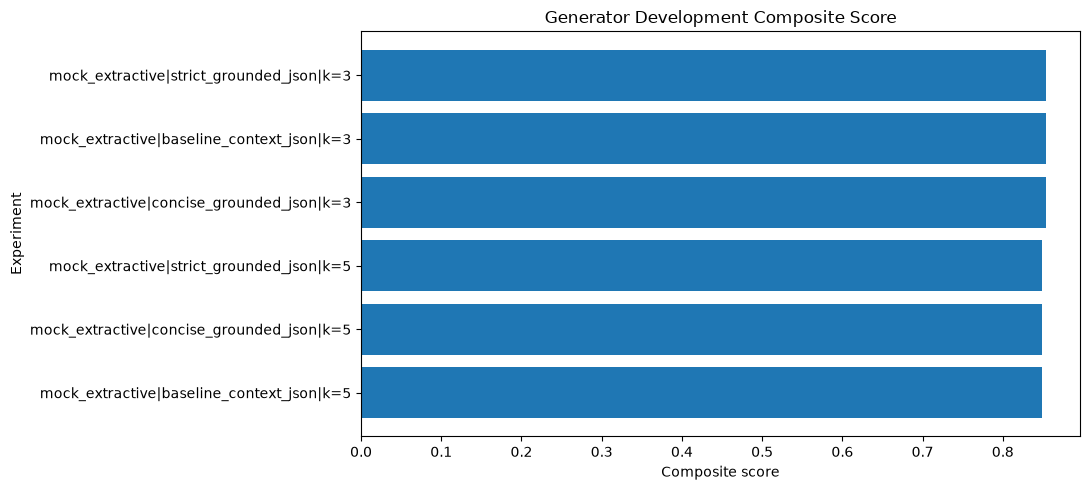

In [45]:
# Composite score.
composite_plot_df = experiment_comparison_df.sort_values(
    "development_composite_score"
)

plt.figure(
    figsize=(11, max(5, len(composite_plot_df) * 0.45))
)
plt.barh(
    composite_plot_df["experiment_label"],
    composite_plot_df["development_composite_score"],
)
plt.title("Generator Development Composite Score")
plt.xlabel("Composite score")
plt.ylabel("Experiment")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "generator_composite_score.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

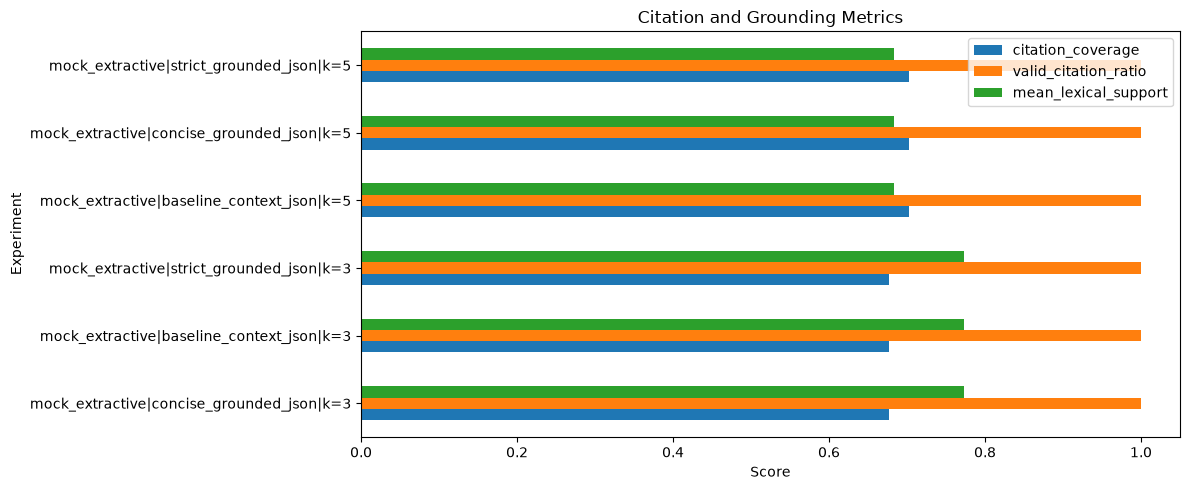

In [46]:
# Citation and faithfulness metrics.
citation_plot_columns = [
    "citation_coverage",
    "valid_citation_ratio",
    "mean_lexical_support",
]

citation_plot_df = experiment_comparison_df.set_index(
    "experiment_label"
)[citation_plot_columns].fillna(0.0)

plt.figure(
    figsize=(12, max(5, len(citation_plot_df) * 0.5))
)
citation_plot_df.plot(
    kind="barh",
    ax=plt.gca(),
)
plt.title("Citation and Grounding Metrics")
plt.xlabel("Score")
plt.ylabel("Experiment")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "citation_grounding_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

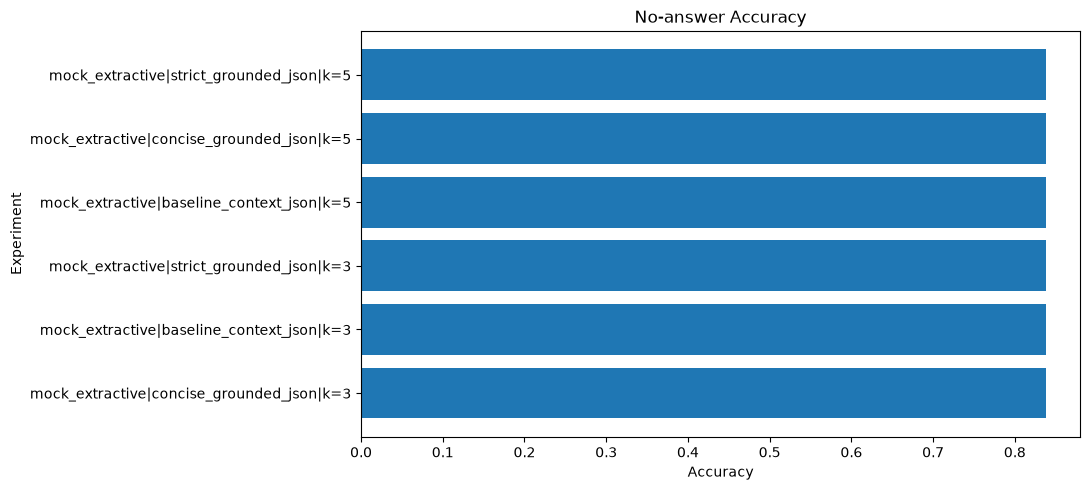

In [47]:
# No-answer accuracy.
no_answer_plot_df = experiment_comparison_df.sort_values(
    "no_answer_accuracy"
)

plt.figure(
    figsize=(11, max(5, len(no_answer_plot_df) * 0.4))
)
plt.barh(
    no_answer_plot_df["experiment_label"],
    no_answer_plot_df["no_answer_accuracy"],
)
plt.title("No-answer Accuracy")
plt.xlabel("Accuracy")
plt.ylabel("Experiment")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "no_answer_accuracy.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

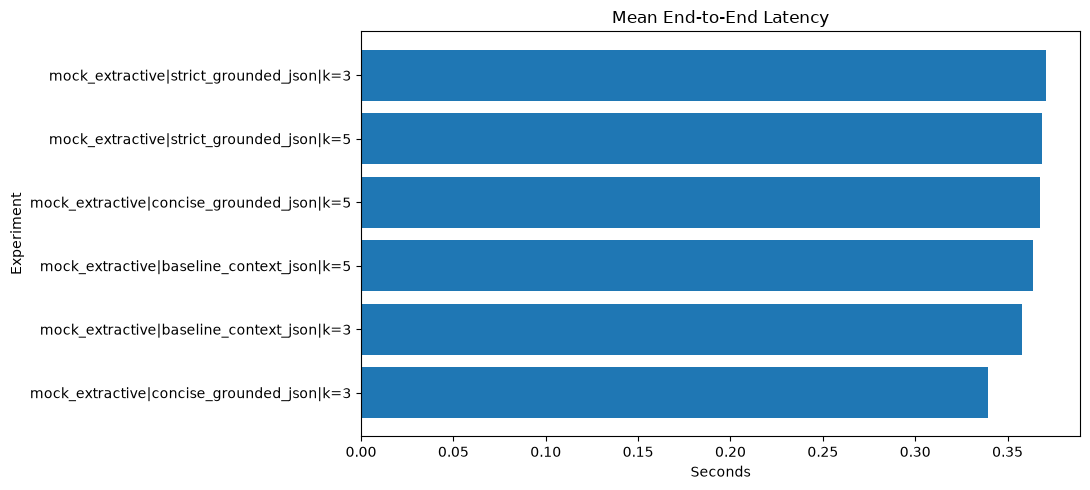

In [48]:
# End-to-end latency.
latency_plot_df = experiment_comparison_df.sort_values(
    "mean_latency_seconds"
)

plt.figure(
    figsize=(11, max(5, len(latency_plot_df) * 0.4))
)
plt.barh(
    latency_plot_df["experiment_label"],
    latency_plot_df["mean_latency_seconds"],
)
plt.title("Mean End-to-End Latency")
plt.xlabel("Seconds")
plt.ylabel("Experiment")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "generation_latency.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

In [49]:
# Cost plot is created only when at least one configured provider has pricing.
cost_plot_df = experiment_comparison_df[
    experiment_comparison_df["total_estimated_cost_usd"] > 0
].sort_values("total_estimated_cost_usd")

if not cost_plot_df.empty:
    plt.figure(
        figsize=(11, max(5, len(cost_plot_df) * 0.4))
    )
    plt.barh(
        cost_plot_df["experiment_label"],
        cost_plot_df["total_estimated_cost_usd"],
    )
    plt.title("Estimated API Cost")
    plt.xlabel("USD")
    plt.ylabel("Experiment")
    plt.tight_layout()
    plt.savefig(
        PATHS["figures"] / "estimated_api_cost.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
else:
    print(
        "Cost plot skipped because provider pricing was not configured "
        "or all enabled providers were free."
    )

Cost plot skipped because provider pricing was not configured or all enabled providers were free.


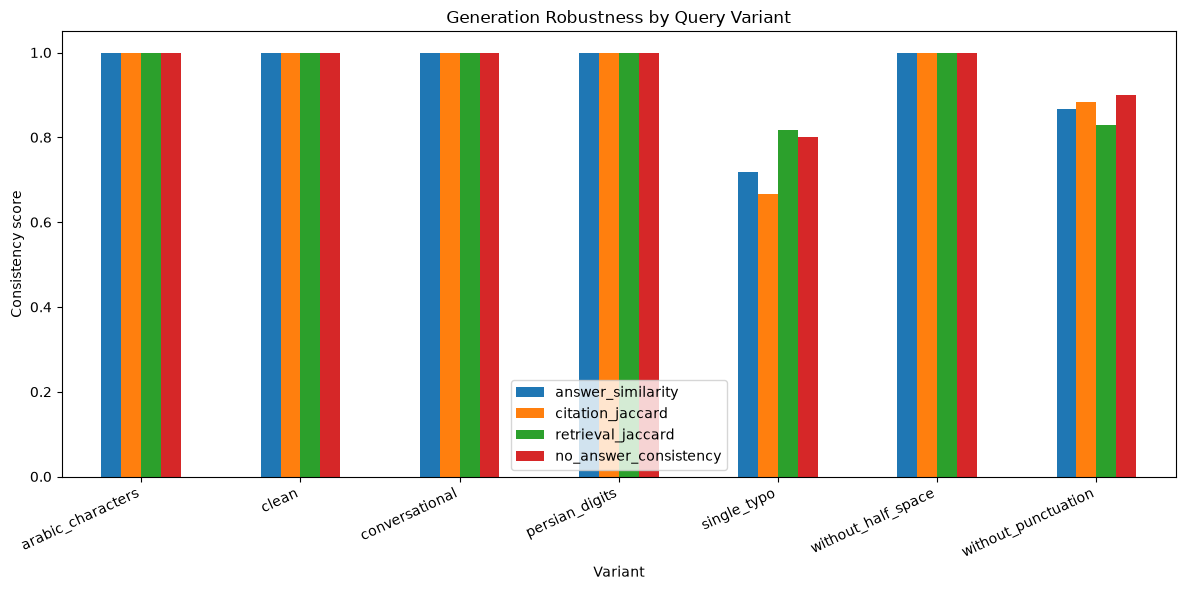

In [50]:
# Robustness plot.
if not robustness_summary_df.empty:
    plot_df = robustness_summary_df.set_index("variant")[
        [
            "answer_similarity",
            "citation_jaccard",
            "retrieval_jaccard",
            "no_answer_consistency",
        ]
    ]

    plt.figure(figsize=(12, 6))
    plot_df.plot(kind="bar", ax=plt.gca())
    plt.title("Generation Robustness by Query Variant")
    plt.xlabel("Variant")
    plt.ylabel("Consistency score")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(
        PATHS["figures"] / "generation_robustness.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

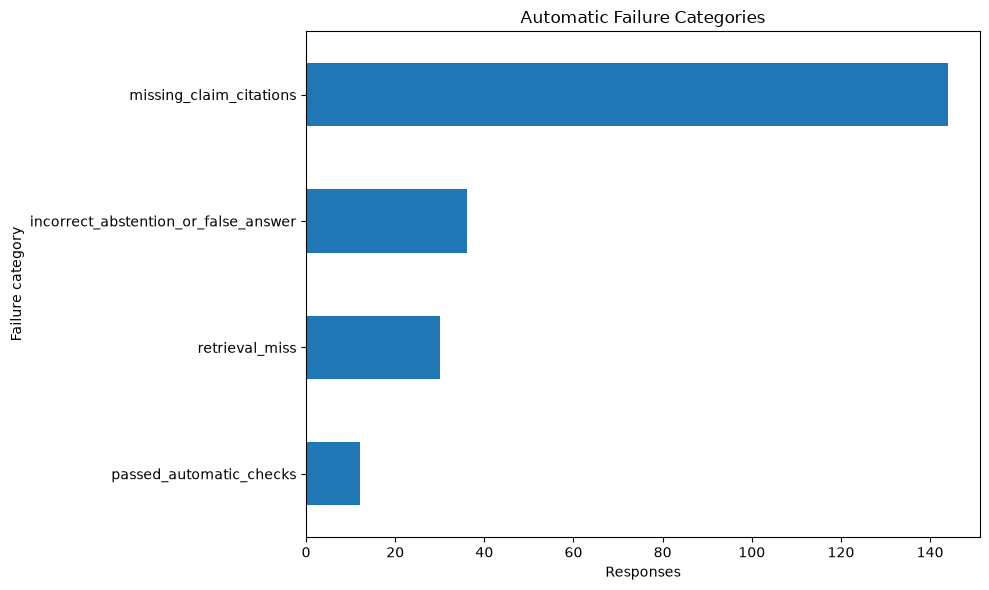

In [51]:
# Failure category distribution.
failure_counts = (
    generation_results_df["failure_category"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))
failure_counts.plot(kind="barh")
plt.title("Automatic Failure Categories")
plt.xlabel("Responses")
plt.ylabel("Failure category")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "generation_failure_categories.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# 25. Export Results and Reproducibility Reports

In [52]:
OUTPUT_PATHS = {
    "generation_results_parquet": (
        PATHS["results"] / "generation_results.parquet"
    ),
    "generation_sources_parquet": (
        PATHS["results"] / "generation_sources.parquet"
    ),
    "experiment_comparison_csv": (
        PATHS["reports"] / "experiment_comparison.csv"
    ),
    "provider_comparison_csv": (
        PATHS["reports"] / "provider_comparison.csv"
    ),
    "prompt_comparison_csv": (
        PATHS["reports"] / "prompt_comparison.csv"
    ),
    "nli_results_csv": (
        PATHS["reports"] / "nli_faithfulness.csv"
    ),
    "llm_judge_csv": (
        PATHS["reports"] / "llm_judge_results.csv"
    ),
    "robustness_results_csv": (
        PATHS["reports"] / "robustness_results.csv"
    ),
    "robustness_summary_csv": (
        PATHS["reports"] / "robustness_summary.csv"
    ),
    "error_analysis_csv": (
        PATHS["reports"] / "generation_error_analysis.csv"
    ),
    "human_evaluation_csv": (
        PATHS["evaluation"] / "human_evaluation_sheet.csv"
    ),
    "best_generator_yaml": (
        PATHS["reports"] / "best_generator_config.yaml"
    ),
    "metrics_json": (
        PATHS["reports"] / "generation_metrics.json"
    ),
    "generation_summary_json": (
        PATHS["reports"] / "generation_summary.json"
    ),
    "execution_report_json": (
        PATHS["reports"] / "execution_report.json"
    ),
}


def json_safe_value(value: Any) -> Any:
    if isinstance(value, dict):
        return {
            str(key): json_safe_value(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe_value(item)
            for item in value
        ]

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return (
            None
            if not np.isfinite(value)
            else float(value)
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, Path):
        return str(value)

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return value


def dataframe_for_parquet(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    output = dataframe.copy()

    for column in output.columns:
        contains_nested = output[column].map(
            lambda value: isinstance(
                value,
                (list, dict, tuple, set),
            )
        ).any()

        if contains_nested:
            output[column] = output[column].map(
                lambda value: json.dumps(
                    json_safe_value(value),
                    ensure_ascii=False,
                )
                if isinstance(value, (list, dict, tuple, set))
                else value
            )

    return output

In [53]:
with timed_stage("export_generation_results"):
    dataframe_for_parquet(
        generation_results_df
    ).to_parquet(
        OUTPUT_PATHS["generation_results_parquet"],
        index=False,
        engine="pyarrow",
    )

    dataframe_for_parquet(
        generation_sources_df
    ).to_parquet(
        OUTPUT_PATHS["generation_sources_parquet"],
        index=False,
        engine="pyarrow",
    )

    experiment_comparison_df.to_csv(
        OUTPUT_PATHS["experiment_comparison_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    provider_comparison_df.to_csv(
        OUTPUT_PATHS["provider_comparison_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    prompt_comparison_df.to_csv(
        OUTPUT_PATHS["prompt_comparison_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    nli_results_df.to_csv(
        OUTPUT_PATHS["nli_results_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    llm_judge_df.to_csv(
        OUTPUT_PATHS["llm_judge_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    robustness_df.to_csv(
        OUTPUT_PATHS["robustness_results_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    robustness_summary_df.to_csv(
        OUTPUT_PATHS["robustness_summary_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    error_analysis_df.to_csv(
        OUTPUT_PATHS["error_analysis_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    human_evaluation_df.to_csv(
        OUTPUT_PATHS["human_evaluation_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    OUTPUT_PATHS["best_generator_yaml"].write_text(
        yaml.safe_dump(
            BEST_GENERATOR_CONFIG,
            allow_unicode=True,
            sort_keys=False,
        ),
        encoding="utf-8",
    )

INFO | START STAGE: export_generation_results
INFO | END STAGE: export_generation_results | 0.081 sec


In [54]:
METRICS_EXPORT = {
    "active_benchmark_path": str(
        ACTIVE_GENERATION_BENCHMARK_PATH
    ),
    "benchmark_type": str(
        generation_evaluation_df["benchmark_type"].iloc[0]
    ),
    "query_count": int(len(generation_evaluation_df)),
    "experiment_comparison": (
        experiment_comparison_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "provider_comparison": (
        provider_comparison_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "prompt_comparison": (
        prompt_comparison_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "nli_status": NLI_STATUS,
    "nli_results": (
        nli_results_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "llm_judge_results": (
        llm_judge_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "robustness_summary": (
        robustness_summary_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "best_generator": BEST_GENERATOR_CONFIG,
}

OUTPUT_PATHS["metrics_json"].write_text(
    json.dumps(
        json_safe_value(METRICS_EXPORT),
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

17231

In [55]:
TOTAL_RUNTIME_SECONDS = round(
    time.perf_counter() - PIPELINE_STARTED_AT,
    3,
)

GENERATION_SUMMARY = {
    "run_id": RUN_ID,
    "status": (
        "completed_with_errors"
        if PIPELINE_ERRORS
        else "completed_with_warnings"
        if PIPELINE_WARNINGS
        else "completed"
    ),
    "benchmark_type": str(
        generation_evaluation_df["benchmark_type"].iloc[0]
    ),
    "benchmark_queries": int(
        len(generation_evaluation_df)
    ),
    "providers_ready": sorted(PROVIDERS),
    "prompt_variants": ENABLED_PROMPT_VARIANTS,
    "experiments": int(
        generation_results_df["experiment_label"].nunique()
    ),
    "generated_responses": int(
        len(generation_results_df)
    ),
    "best_generator": BEST_GENERATOR_CONFIG,
    "generator_selection_status": GENERATOR_SELECTION_STATUS,
    "production_ready": PRODUCTION_READY,
    "reference_answer_coverage": REFERENCE_ANSWER_COVERAGE,
    "automatic_failure_rows": int(
        len(error_analysis_df)
    ),
    "human_evaluation_rows": int(
        len(human_evaluation_df)
    ),
    "errors_count": len(PIPELINE_ERRORS),
    "warnings_count": len(PIPELINE_WARNINGS),
    "total_runtime_seconds": TOTAL_RUNTIME_SECONDS,
    "backend_inputs": {
        "chunks": str(PATHS["chunks"]),
        "index_manifest": str(PATHS["index_manifest"]),
        "best_retriever": str(PATHS["best_retriever"]),
        "best_generator": str(
            OUTPUT_PATHS["best_generator_yaml"]
        ),
    },
}

EXECUTION_REPORT = {
    **ENVIRONMENT_INFO,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(),
    "total_runtime_seconds": TOTAL_RUNTIME_SECONDS,
    "stage_timings_seconds": STAGE_TIMINGS,
    "config": CONFIG,
    "input_validation": INPUT_VALIDATION,
    "provider_initialization": provider_initialization_rows,
    "best_retriever": best_retriever_config,
    "best_generator": BEST_GENERATOR_CONFIG,
    "generator_selection_status": GENERATOR_SELECTION_STATUS,
    "production_ready": PRODUCTION_READY,
    "active_generation_benchmark": str(
        ACTIVE_GENERATION_BENCHMARK_PATH
    ),
    "output_paths": {
        key: str(path)
        for key, path in OUTPUT_PATHS.items()
    },
    "log_path": str(LOG_PATH),
    "errors": PIPELINE_ERRORS,
    "warnings": PIPELINE_WARNINGS,
}

OUTPUT_PATHS["generation_summary_json"].write_text(
    json.dumps(
        json_safe_value(GENERATION_SUMMARY),
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

OUTPUT_PATHS["execution_report_json"].write_text(
    json.dumps(
        json_safe_value(EXECUTION_REPORT),
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

display(
    pd.DataFrame([GENERATION_SUMMARY]).T.rename(
        columns={0: "value"}
    )
)

,value
run_id,20260715_022238
status,completed
benchmark_type,generation_silver
benchmark_queries,37
providers_ready,[mock_extractive]
prompt_variants,"[strict_grounded_json, concise_grounded_json, ..."
experiments,6
generated_responses,222
best_generator,"{'benchmark_type': 'generation_silver', 'selec..."
generator_selection_status,mock_smoke_test_only


# 26. Final Integrity Check

The notebook verifies:

- required exports exist;
- result row counts are preserved;
- every citation refers to an existing source;
- the selected provider is ready;
- Parquet files can be loaded;
- the final system returns the expected fields.

In [56]:
REQUIRED_OUTPUT_KEYS = [
    "generation_results_parquet",
    "generation_sources_parquet",
    "experiment_comparison_csv",
    "provider_comparison_csv",
    "prompt_comparison_csv",
    "error_analysis_csv",
    "human_evaluation_csv",
    "best_generator_yaml",
    "metrics_json",
    "generation_summary_json",
    "execution_report_json",
]

missing_outputs = [
    key
    for key in REQUIRED_OUTPUT_KEYS
    if not OUTPUT_PATHS[key].exists()
]

if missing_outputs:
    raise AssertionError(
        f"Required generation outputs are missing: {missing_outputs}"
    )

reloaded_results = pd.read_parquet(
    OUTPUT_PATHS["generation_results_parquet"],
    engine="pyarrow",
)
reloaded_sources = pd.read_parquet(
    OUTPUT_PATHS["generation_sources_parquet"],
    engine="pyarrow",
)

assert len(reloaded_results) == len(generation_results_df)
assert len(reloaded_sources) == len(generation_sources_df)
assert BEST_GENERATOR_CONFIG["provider_alias"] in PROVIDERS

invalid_citation_total = int(
    pd.to_numeric(
        generation_results_df["invalid_citation_count"],
        errors="coerce",
    ).fillna(0).sum()
)

required_runtime_fields = {
    "question",
    "answer",
    "citations",
    "sources",
    "no_answer",
    "provider_alias",
    "model",
    "retriever_method",
    "latency_seconds",
}

assert required_runtime_fields.issubset(
    backend_smoke_test.keys()
)

print("✅ Generation and evaluation outputs passed the integrity check.")
print("Invalid citations detected across experiments:", invalid_citation_total)
print()

for name, path in OUTPUT_PATHS.items():
    marker = "✅" if path.exists() else "❌"
    size_mb = (
        round(path.stat().st_size / (1024 ** 2), 4)
        if path.exists()
        else None
    )
    print(f"{marker} {name}: {path} | {size_mb} MB")

# Corrected metric bounds.
BOUNDED_METRIC_COLUMNS = [
    "context_precision",
    "context_recall",
    "context_hit",
    "generation_success",
    "nonempty_answer",
    "parse_success",
    "no_answer_accuracy",
    "no_answer_format_valid",
    "valid_citation_ratio",
    "citation_coverage",
    "citation_list_consistency",
]

for column in BOUNDED_METRIC_COLUMNS:
    values = pd.to_numeric(
        generation_results_df[column],
        errors="coerce",
    ).dropna()
    assert values.between(0.0, 1.0).all(), (
        f"{column} contains a value outside [0, 1]."
    )

failed_rows = generation_results_df[
    generation_results_df["provider_failed"].astype(bool)
    | generation_results_df["empty_answer"].astype(bool)
]
if not failed_rows.empty:
    assert (
        pd.to_numeric(
            failed_rows["no_answer_accuracy"],
            errors="coerce",
        ).fillna(0.0)
        == 0.0
    ).all()
    assert (
        pd.to_numeric(
            failed_rows["citation_coverage"],
            errors="coerce",
        ).fillna(0.0)
        == 0.0
    ).all()

assert BEST_GENERATOR_CONFIG["selection_status"] in {
    "final_gold_candidate",
    "mock_smoke_test_only",
    "provisional_silver",
    "provisional_failed_thresholds",
    "provisional_manual_review_required",
}

if BEST_GENERATOR_CONFIG["production_ready"]:
    assert BEST_GENERATOR_CONFIG["provider_name"] != "mock"
    assert BEST_GENERATOR_CONFIG["eligible_for_selection"]
    assert (
        BEST_GENERATOR_CONFIG["benchmark_type"]
        == "generation_gold"
    )
    assert (
        best_retriever_config["selection_status"]
        == "final_gold"
    )

print(
    "Generator selection status:",
    BEST_GENERATOR_CONFIG["selection_status"],
)
print(
    "Production ready:",
    BEST_GENERATOR_CONFIG["production_ready"],
)

✅ Generation and evaluation outputs passed the integrity check.
Invalid citations detected across experiments: 0

✅ generation_results_parquet: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\results\generation_results.parquet | 0.1174 MB
✅ generation_sources_parquet: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\results\generation_sources.parquet | 0.1438 MB
✅ experiment_comparison_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\reports\experiment_comparison.csv | 0.003 MB
✅ provider_comparison_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\reports\provider_comparison.csv | 0.0004 MB
✅ prompt_comparison_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\reports\prompt_comparison.csv | 0.001 MB
✅ nli_results_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\reports\nli_faithfulness.csv | 0.0 MB
✅ llm_judge_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\reports\llm_judge_results.c

In [57]:
print("=" * 78)
print("UNIVERSITY RAG — GENERATION AND EVALUATION COMPLETED")
print("=" * 78)
print(f"Benchmark queries       : {GENERATION_SUMMARY['benchmark_queries']}")
print(f"Benchmark type          : {GENERATION_SUMMARY['benchmark_type']}")
print(
    "Providers ready        : "
    f"{', '.join(GENERATION_SUMMARY['providers_ready'])}"
)
print(f"Experiments             : {GENERATION_SUMMARY['experiments']}")
print(f"Generated responses     : {GENERATION_SUMMARY['generated_responses']}")
print(
    "Best generator         : "
    f"{BEST_GENERATOR_CONFIG['experiment_label']}"
)
print(
    "Selection status       : "
    f"{BEST_GENERATOR_CONFIG['selection_status']}"
)
print(
    "Production ready       : "
    f"{BEST_GENERATOR_CONFIG['production_ready']}"
)
print(
    "Automatic failure rows : "
    f"{GENERATION_SUMMARY['automatic_failure_rows']}"
)
print(f"Errors                  : {GENERATION_SUMMARY['errors_count']}")
print(f"Warnings                : {GENERATION_SUMMARY['warnings_count']}")
print(
    "Runtime (seconds)      : "
    f"{GENERATION_SUMMARY['total_runtime_seconds']}"
)
print(
    "Backend config         : "
    f"{OUTPUT_PATHS['best_generator_yaml']}"
)
print("=" * 78)

UNIVERSITY RAG — GENERATION AND EVALUATION COMPLETED
Benchmark queries       : 37
Benchmark type          : generation_silver
Providers ready        : mock_extractive
Experiments             : 6
Generated responses     : 222
Best generator         : mock_extractive|concise_grounded_json|k=3
Selection status       : mock_smoke_test_only
Production ready       : False
Automatic failure rows : 210
Errors                  : 0
Warnings                : 0
Runtime (seconds)      : 163.155
Backend config         : D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\generation\reports\best_generator_config.yaml


# References and API Notes

The provider adapters follow the official SDK patterns current when this notebook was prepared:

- OpenAI Python SDK and Responses API:  
  `https://developers.openai.com/api/docs/quickstart`

- Anthropic Messages API and current model overview:  
  `https://platform.claude.com/docs/en/get-started`  
  `https://platform.claude.com/docs/en/about-claude/models/overview`

- Google GenAI Python SDK and Gemini API quickstart:  
  `https://ai.google.dev/gemini-api/docs/get-started`

Model IDs and prices can change. Keep provider names and pricing in `generation_config.yaml`, not inside the evaluation logic.